In [ ]:
!pip install -q sentence-transformers faiss-cpu datasets scipy nltk
import os
import re
import math
import time
import json
import platform
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import spearmanr, wilcoxon
import nltk
from nltk.stem import PorterStemmer
import torch
import faiss
import datasets
import sentence_transformers
from sentence_transformers import SentenceTransformer

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 20)
np.random.seed(42)
torch.manual_seed(42)

print("=== REPRODUCIBILITY ENVIRONMENT ===")
print(f"Python:                {platform.python_version()}")
print(f"PyTorch:               {torch.__version__} (CUDA: {torch.cuda.is_available()})")
print(f"FAISS:                 {faiss.__version__}")
print(f"Sentence-Transformers: {sentence_transformers.__version__}")
print(f"HuggingFace Datasets:  {datasets.__version__}")
print(f"SciPy / NumPy:         {scipy.__version__} / {np.__version__}")

=== REPRODUCIBILITY ENVIRONMENT ===
Python:                3.13.16
PyTorch:               2.11.0+cu130 (CUDA: True)
FAISS:                 1.15.1
Sentence-Transformers: 5.7.0
HuggingFace Datasets:  4.8.5
SciPy / NumPy:         1.16.3 / 2.4.6


In [ ]:
DATASET_FILES = [
    "News_Category_Dataset_v3.json.zip",
    "News_Category_Dataset_v3.json",
    "news_corpus.csv"
]

loaded_path = next((p for p in DATASET_FILES if os.path.exists(p)), None)
if loaded_path is None:
    try:
        from google.colab import files
        print("Please upload News_Category_Dataset_v3.json.zip (or .json):")
        uploaded = files.upload()
        loaded_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("Place News_Category_Dataset_v3.json.zip in the working directory.")

if loaded_path.endswith(".csv"):
    df = pd.read_csv(loaded_path)
    df = df.reset_index(drop=True)
    if "doc_id" not in df.columns:
        df["doc_id"] = [f"N{i:06d}" for i in range(len(df))]
else:
    df = pd.read_json(loaded_path, lines=True)
    df = df.reset_index(drop=True)
    df["doc_id"] = [f"N{i:06d}" for i in range(len(df))]

df["headline"] = df["headline"].fillna("").astype(str)
df["short_description"] = df["short_description"].fillna("").astype(str)
df["category"] = df["category"].fillna("UNKNOWN").astype(str)
df["search_text"] = (
    df["headline"].str.strip() + ". " + df["short_description"].str.strip()
).str.strip()

df["is_recurring_series"] = df["headline"].str.contains(
    r"Funniest Tweets (?:About Cats And Dogs|From Parents|From Women) This Week",
    case=False, regex=True, na=False
)

doc_id_to_idx = {doc_id: idx for idx, doc_id in enumerate(df["doc_id"])}
idx_to_doc_id = df["doc_id"].to_numpy()

print(f"Corpus loaded from '{loaded_path}': {df.shape[0]:,} documents.")
print(f"Recurring weekly tweet roundups flagged: {int(df['is_recurring_series'].sum()):,}")
display(df[["doc_id", "headline", "short_description", "category", "date"]].head(5))

Please upload News_Category_Dataset_v3.json.zip (or .json):


Saving News_Category_Dataset_v3.json.zip to News_Category_Dataset_v3.json.zip
Corpus loaded from 'News_Category_Dataset_v3.json.zip': 209,527 documents.
Recurring weekly tweet roundups flagged: 231


,doc_id,headline,short_description,category,date
0,N000000,Over 4 Million Americans Roll Up Sleeves For Omicron-Targeted COVID Boosters,Health experts said it is too early to predict whether demand would match up with the 171 million doses of the new boosters the U.S. ord...,U.S. NEWS,2022-09-23
1,N000001,"American Airlines Flyer Charged, Banned For Life After Punching Flight Attendant On Video","He was subdued by passengers and crew when he fled to the back of the aircraft after the confrontation, according to the U.S. attorney's...",U.S. NEWS,2022-09-23
2,N000002,23 Of The Funniest Tweets About Cats And Dogs This Week (Sept. 17-23),"""Until you have a dog you don't understand what could be eaten.""",COMEDY,2022-09-23
3,N000003,The Funniest Tweets From Parents This Week (Sept. 17-23),"""Accidentally put grown-up toothpaste on my toddler’s toothbrush and he screamed like I was cleaning his teeth with a Carolina Reaper di...",PARENTING,2022-09-23
4,N000004,Woman Who Called Cops On Black Bird-Watcher Loses Lawsuit Against Ex-Employer,Amy Cooper accused investment firm Franklin Templeton of unfairly firing her and branding her a racist after video of the Central Park e...,U.S. NEWS,2022-09-22


In [ ]:
STOPWORDS = {
    "a", "about", "above", "after", "again", "against", "all", "almost", "alone", "along",
    "already", "also", "although", "always", "am", "among", "an", "and", "another", "any",
    "anybody", "anyone", "anything", "anywhere", "are", "area", "areas", "around", "as",
    "ask", "asked", "asking", "asks", "at", "away", "b", "back", "backed", "backing",
    "backs", "be", "became", "because", "become", "becomes", "been", "before", "began",
    "behind", "being", "beings", "best", "better", "between", "big", "both", "but", "by",
    "c", "came", "can", "cannot", "case", "cases", "certain", "certainly", "clear", "clearly",
    "come", "could", "d", "did", "differ", "different", "differently", "do", "does", "done",
    "down", "downed", "downing", "downs", "during", "e", "each", "early", "either", "end",
    "ended", "ending", "ends", "enough", "even", "evenly", "ever", "every", "everybody",
    "everyone", "everything", "everywhere", "f", "face", "faces", "fact", "facts", "far",
    "felt", "few", "find", "finds", "first", "for", "four", "from", "full", "fully",
    "further", "furthered", "furthering", "furthers", "g", "gave", "general", "generally",
    "get", "gets", "give", "given", "gives", "go", "going", "good", "goods", "got", "great",
    "greater", "greatest", "group", "grouped", "grouping", "groups", "h", "had", "has", "have",
    "having", "he", "her", "here", "herself", "high", "higher", "highest", "him", "himself",
    "his", "how", "however", "i", "if", "important", "in", "interest", "interested",
    "interesting", "interests", "into", "is", "it", "its", "itself", "j", "just", "k", "keep",
    "keeps", "kind", "knew", "know", "known", "knows", "l", "large", "largely", "last",
    "later", "latest", "least", "less", "let", "lets", "like", "likely", "long", "longer",
    "longest", "m", "made", "make", "making", "man", "many", "may", "me", "member", "members",
    "men", "might", "more", "most", "mostly", "mr", "mrs", "much", "must", "my", "myself",
    "n", "necessary", "need", "needed", "needing", "needs", "never", "new", "newer", "newest",
    "next", "no", "nobody", "non", "noone", "not", "nothing", "now", "nowhere", "number",
    "numbers", "o", "of", "off", "often", "old", "older", "oldest", "on", "once", "one",
    "only", "open", "opened", "opening", "opens", "or", "order", "ordered", "ordering",
    "orders", "other", "others", "our", "out", "over", "p", "part", "parted", "parting",
    "parts", "per", "perhaps", "place", "places", "point", "pointed", "pointing", "points",
    "possible", "present", "presented", "presenting", "presents", "problem", "problems",
    "put", "puts", "q", "quite", "r", "rather", "really", "right", "room", "rooms", "s",
    "said", "same", "saw", "say", "says", "second", "seconds", "see", "seem", "seemed",
    "seeming", "seems", "sees", "several", "shall", "she", "should", "show", "showed",
    "showing", "shows", "side", "sides", "since", "small", "smaller", "smallest", "so",
    "some", "somebody", "someone", "something", "somewhere", "state", "states", "still",
    "such", "sure", "t", "take", "taken", "than", "that", "the", "their", "them", "then",
    "there", "therefore", "these", "they", "thing", "things", "think", "thinks", "this",
    "those", "though", "thought", "thoughts", "three", "through", "thus", "to", "today",
    "together", "too", "took", "toward", "turn", "turned", "turning", "turns", "two", "u",
    "under", "until", "up", "upon", "us", "use", "used", "uses", "v", "very", "w", "want",
    "wanted", "wanting", "wants", "was", "way", "ways", "we", "well", "wells", "went", "were",
    "what", "when", "where", "whether", "which", "while", "who", "whole", "whose", "why",
    "will", "with", "within", "without", "work", "worked", "working", "works", "would",
    "x", "y", "year", "years", "yet", "you", "young", "younger", "youngest", "your", "yours", "z"
}

TOKEN_PATTERN = re.compile(r"\b[a-z0-9]+(?:-[a-z0-9]+)*\b")
stemmer = PorterStemmer()
STEM_CACHE = {}

def stem_token(tok):
    if tok not in STEM_CACHE:
        STEM_CACHE[tok] = stemmer.stem(tok)
    return STEM_CACHE[tok]

def custom_tokenize(text, remove_stopwords=True, use_stemming=False):
    tokens = TOKEN_PATTERN.findall(str(text).lower())
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 1]
    if use_stemming:
        tokens = [stem_token(t) for t in tokens]
    return tokens


class ScratchBM25Engine:
    def __init__(self, k1=1.5, b=0.75, use_stemming=False, name="BM25"):
        self.k1 = k1
        self.b = b
        self.use_stemming = use_stemming
        self.name = name
        self.N = 0
        self.avgdl = 0.0
        self.doc_len = None
        self.doc_token_sets = []
        self.df_table = {}
        self.idf_table = {}
        self.inverted_index = {}
        self.index_time_sec = 0.0

    def fit(self, corpus_texts):
        t0 = time.time()
        self.N = len(corpus_texts)
        self.doc_len = np.zeros(self.N, dtype=np.int32)
        self.doc_token_sets = [None] * self.N
        temp_postings = defaultdict(lambda: ([], []))

        for doc_idx, text in enumerate(corpus_texts):
            tokens = custom_tokenize(text, remove_stopwords=True, use_stemming=self.use_stemming)
            self.doc_len[doc_idx] = len(tokens)
            self.doc_token_sets[doc_idx] = set(tokens)
            tf_counter = Counter(tokens)
            for term, tf in tf_counter.items():
                doc_list, tf_list = temp_postings[term]
                doc_list.append(doc_idx)
                tf_list.append(tf)

        self.avgdl = float(np.mean(self.doc_len))
        for term, (doc_list, tf_list) in temp_postings.items():
            df_t = len(doc_list)
            self.df_table[term] = df_t
            self.idf_table[term] = math.log(1.0 + (self.N - df_t + 0.5) / (df_t + 0.5))
            self.inverted_index[term] = (
                np.array(doc_list, dtype=np.int32),
                np.array(tf_list, dtype=np.float32)
            )

        self.index_time_sec = time.time() - t0
        print(
            f"[{self.name}] Indexed {self.N:,} docs | "
            f"Vocab: {len(self.inverted_index):,} | "
            f"AvgDL: {self.avgdl:.2f} | "
            f"Time: {self.index_time_sec:.2f}s"
        )
        return self

    def score_all(self, query_text):
        q_tokens = custom_tokenize(query_text, remove_stopwords=True, use_stemming=self.use_stemming)
        scores = np.zeros(self.N, dtype=np.float32)
        if not q_tokens:
            return scores
        q_term_counts = Counter(q_tokens)
        for term, q_tf in q_term_counts.items():
            if term not in self.inverted_index:
                continue
            doc_indices, doc_tfs = self.inverted_index[term]
            idf = self.idf_table[term]
            d_lens = self.doc_len[doc_indices]
            norm_factor = self.k1 * (1.0 - self.b + self.b * (d_lens / self.avgdl))
            term_scores = idf * ((doc_tfs * (self.k1 + 1.0)) / (doc_tfs + norm_factor)) * q_tf
            scores[doc_indices] += term_scores
        return scores

    def search(self, query_text, top_k=100):
        scores = self.score_all(query_text)
        pos_count = int((scores > 0).sum())
        k = min(top_k, pos_count)
        if k == 0:
            return np.array([], dtype=np.int32), np.array([], dtype=np.float32)
        idx = np.argpartition(scores, -k)[-k:]
        idx = idx[np.argsort(scores[idx])[::-1]]
        return idx.astype(np.int32), scores[idx]


corpus_list = df["search_text"].tolist()
bm25_engine = ScratchBM25Engine(k1=1.5, b=0.75, use_stemming=False, name="Engine A1: BM25 (Unstemmed)").fit(corpus_list)
bm25_stemmed_engine = ScratchBM25Engine(k1=1.5, b=0.75, use_stemming=True, name="Engine A2: BM25 (Porter Stemmed)").fit(corpus_list)

[Engine A1: BM25 (Unstemmed)] Indexed 209,527 docs | Vocab: 107,253 | AvgDL: 14.84 | Time: 16.26s
[Engine A2: BM25 (Porter Stemmed)] Indexed 209,527 docs | Vocab: 80,792 | AvgDL: 14.84 | Time: 25.30s


In [ ]:
QUERY_SPECIFICATIONS = [
    {
        "query_id": "Q01",
        "query": "automobile manufacturer recalls defective vehicles over fatal crash hazards",
        "taxonomy_subtype": "Synonym Mismatch",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": [],
        "must_match_any": ["general motors", "gm recall", "ignition switch", "takata airbag", "toyota recall"],
        "topic_keywords": ["general motors", "ignition switch", "recall", "airbag", "automaker", "defective", "deaths"]
    },
    {
        "query_id": "Q02",
        "query": "physicians warn about chronic sleep deprivation and daytime exhaustion",
        "taxonomy_subtype": "Synonym Mismatch",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": [],
        "must_match_any": ["sleep deprivation", "insomnia", "lack of sleep", "sleep apnea", "getting enough sleep"],
        "topic_keywords": ["sleep deprivation", "insomnia", "lack of sleep", "sleep habits", "hours of sleep", "exhaustion"]
    },
    {
        "query_id": "Q03",
        "query": "escalating consumer grocery prices and household cost of living squeeze",
        "taxonomy_subtype": "Synonym Mismatch",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N000243"],
        "must_match_any": ["inflation", "food prices", "grocery", "cost of living", "consumer prices"],
        "topic_keywords": ["inflation", "food prices", "grocery", "cost of living", "consumer prices", "supermarket"]
    },
    {
        "query_id": "Q04",
        "query": "severe Caribbean tropical cyclone causes island utility blackouts and mudslides",
        "taxonomy_subtype": "Hypernym/Hyponym Mismatch",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N000007", "N000012", "N000019", "N000022", "N000035"],
        "must_match_any": ["hurricane fiona", "tropical storm fiona"],
        "topic_keywords": ["hurricane fiona", "puerto rico", "power grid", "without water", "landslides", "dominican republic"]
    },
    {
        "query_id": "Q05",
        "query": "domestic canines and felines amusing pet owners on social media",
        "taxonomy_subtype": "Hypernym/Hyponym Mismatch",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N000002"],
        "must_match_any": ["tweets about cats and dogs", "hilarious dog", "funny cat", "dogs who", "cats who"],
        "topic_keywords": ["cats and dogs", "funny tweets", "dog", "cat", "hilarious", "barkpost"]
    },
    {
        "query_id": "Q06",
        "query": "firearm legislation debates after mass casualties at educational institutions",
        "taxonomy_subtype": "Hypernym/Hyponym Mismatch",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N029057", "N008398"],
        "must_match_any": ["gun control", "school shooting", "parkland", "sandy hook", "assault weapons"],
        "topic_keywords": ["gun control", "second amendment", "school shooting", "parkland", "ar-15", "nra"]
    },
    {
        "query_id": "Q07",
        "query": "human chemosensory olfactory sweat compounds influencing male social cooperation",
        "taxonomy_subtype": "Scientific-vs-Colloquial",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N163649"],
        "must_match_any": ["pheromone", "androstadienone", "body odor", "sense of smell", "sweat"],
        "topic_keywords": ["androstadienone", "pheromone", "sweat", "body odor", "olfactory", "scent"]
    },
    {
        "query_id": "Q08",
        "query": "supplemental immunization efficacy against mutated SARS-CoV-2 lineages in older cohorts",
        "taxonomy_subtype": "Scientific-vs-Colloquial",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N000000", "N000935", "N001497", "N001673", "N002384"],
        "must_match_any": ["covid booster", "covid-19 booster", "second covid booster", "omicron-targeted"],
        "topic_keywords": ["covid booster", "omicron", "fourth coronavirus vaccine", "50 and older", "fauci"]
    },
    {
        "query_id": "Q09",
        "query": "unruly aviation traveler physically assaults cabin crew and receives permanent ban",
        "taxonomy_subtype": "Paraphrase",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N000001", "N001613", "N002542"],
        "must_match_any": ["flight attendant", "unruly passenger", "banned for life"],
        "topic_keywords": ["punching flight attendant", "banned for life", "subdued by passengers", "flight attendant", "plane"]
    },
    {
        "query_id": "Q10",
        "query": "regional carrier cabin personnel threaten work stoppage over unlivable compensation",
        "taxonomy_subtype": "Paraphrase",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N001797", "N001560", "N002518", "N007453", "N010928"],
        "must_match_any": ["threaten to strike", "stages walkout", "avoid strike", "massive strike"],
        "topic_keywords": ["piedmont airlines", "threaten to strike", "wages are too low", "stages walkout", "striking workers", "union"]
    },
    {
        "query_id": "Q11",
        "query": "fossil fuel conduit faces tribal sacred water litigation and covert sabotage reports",
        "taxonomy_subtype": "Paraphrase",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N004331", "N030134", "N033702", "N039950", "N040479"],
        "must_match_any": ["dakota access pipeline", "dakota access"],
        "topic_keywords": ["dakota access pipeline", "standing rock", "native american tribe", "energy transfer partners", "oil"]
    },
    {
        "query_id": "Q12",
        "query": "corporate dismissal and defamation litigation after viral park racial profiling incident",
        "taxonomy_subtype": "Implicit Relevance",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N000004", "N008898"],
        "must_match_any": ["amy cooper", "bird-watcher", "calling police on black", "called cops on black"],
        "topic_keywords": ["amy cooper", "franklin templeton", "central park", "bird-watcher", "called cops", "racism"]
    },
    {
        "query_id": "Q13",
        "query": "commercial carriers tighten cabin rules on exotic comfort pets brought by flyers",
        "taxonomy_subtype": "Implicit Relevance",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N009289"],
        "must_match_any": ["emotional support", "service animal", "support peacock", "support squirrel"],
        "topic_keywords": ["emotional support", "prohibited animals", "onboard companions", "peacock", "airline", "flight"]
    },
    {
        "query_id": "Q14",
        "query": "breaking inherited behavioral cycles and fostering positive intergenerational habits",
        "taxonomy_subtype": "Implicit Relevance",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N128310"],
        "must_match_any": ["generation changers", "generational trauma", "parenting habits", "family patterns"],
        "topic_keywords": ["family generation changers", "generational", "parents", "upbringing", "children", "family"]
    },
    {
        "query_id": "Q15",
        "query": "United States central bank policymakers hike benchmark borrowing rates",
        "taxonomy_subtype": "Abbreviation/Entity Variation",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": [],
        "must_match_any": ["federal reserve", "fed raises", "fed rate", "interest rate hike", "jerome powell"],
        "topic_keywords": ["federal reserve", "interest rate", "jerome powell", "janet yellen", "rate hike", "inflation"]
    },
    {
        "query_id": "Q16",
        "query": "White House chief executive condemns Moscow military invasion at United Nations assembly",
        "taxonomy_subtype": "Abbreviation/Entity Variation",
        "paradigm_focus": "Vocabulary Mismatch (RQ1)",
        "seed_anchors": ["N000009"],
        "must_match_any": ["biden at un", "russian war", "russian invasion", "un general assembly"],
        "topic_keywords": ["biden", "russian war", "ukraine", "un charter", "putin", "united nations"]
    },
    {
        "query_id": "Q17",
        "query": "Mar-a-Lago search affidavit Department of Justice redacted document Trump sensitive intel",
        "taxonomy_subtype": "Lexical Anchor (Exact Entity)",
        "paradigm_focus": "Lexical Anchor (RQ2 - BM25 Strength)",
        "seed_anchors": ["N000157"],
        "must_match_any": ["mar-a-lago", "classified documents", "search warrant", "fbi search"],
        "topic_keywords": ["mar-a-lago", "affidavit", "redacted", "department of justice", "trump", "classified"]
    },
    {
        "query_id": "Q18",
        "query": "Buffalo supermarket shooting 18-year-old suspect 10 killed Tops Friendly Markets",
        "taxonomy_subtype": "Lexical Anchor (Exact Number/Location)",
        "paradigm_focus": "Lexical Anchor (RQ2 - BM25 Strength)",
        "seed_anchors": ["N000674", "N000675"],
        "must_match_any": ["buffalo gunman", "buffalo suspect", "buffalo supermarket", "tops supermarket"],
        "topic_keywords": ["buffalo", "supermarket", "killed 10", "18-year-old", "shooting", "replacement"]
    },
    {
        "query_id": "Q19",
        "query": "Colin Kaepernick San Francisco 49ers national anthem kneeling protest NFL",
        "taxonomy_subtype": "Lexical Anchor (Exact Proper Noun)",
        "paradigm_focus": "Lexical Anchor (RQ2 - BM25 Strength)",
        "seed_anchors": [],
        "must_match_any": ["colin kaepernick", "kaepernick"],
        "topic_keywords": ["colin kaepernick", "national anthem", "49ers", "kneeling", "nfl", "protest"]
    },
    {
        "query_id": "Q20",
        "query": "Trinidad Caribbean cricket Vatican cricket team Kate Middleton Cricket World Cup",
        "taxonomy_subtype": "Lexical Anchor (Polysemous Entity)",
        "paradigm_focus": "Lexical Anchor (RQ2 - BM25 Strength)",
        "seed_anchors": ["N031024", "N120780", "N134002", "N165365"],
        "must_match_any": ["caribbean cricket", "vatican cricket", "cricket world cup", "two wickets"],
        "topic_keywords": ["caribbean cricket", "vatican cricket", "cricket world cup", "tale of two wickets", "cricket"]
    }
]

corpus_lower = df["search_text"].str.lower()
query_records = []
target_audit_rows = []

for spec in QUERY_SPECIFICATIONS:
    targets = [doc_id for doc_id in spec["seed_anchors"] if doc_id in doc_id_to_idx]
    must_mask = np.zeros(len(df), dtype=bool)
    for m_phrase in spec["must_match_any"]:
        pat = r"(?<!\w)" + re.escape(m_phrase.lower()) + r"(?!\w)"
        must_mask |= corpus_lower.str.contains(pat, regex=True, na=False).to_numpy()
    kw_scores = np.zeros(len(df), dtype=np.int16)
    for kw in spec["topic_keywords"]:
        pat = r"(?<!\w)" + re.escape(kw.lower()) + r"(?!\w)"
        kw_scores += corpus_lower.str.contains(pat, regex=True, na=False).to_numpy(dtype=np.int16)
    valid_scores = np.where(must_mask & (~df["is_recurring_series"].to_numpy()), kw_scores, 0)
    best_idx = np.argsort(valid_scores)[::-1]

    for idx in best_idx:
        if len(targets) >= 5:
            break
        if valid_scores[idx] <= 0:
            break
        cand_id = idx_to_doc_id[idx]
        if cand_id not in targets:
            targets.append(cand_id)

    if len(targets) < 4:
        fallback_idx = np.argsort(np.where(~df["is_recurring_series"].to_numpy(), kw_scores, 0))[::-1]
        for idx in fallback_idx:
            if len(targets) >= 4 or kw_scores[idx] <= 1:
                break
            cand_id = idx_to_doc_id[idx]
            if cand_id not in targets:
                targets.append(cand_id)

    targets = targets[:5]
    for t_id in targets:
        t_row = df.loc[doc_id_to_idx[t_id]]
        target_audit_rows.append({
            "query_id": spec["query_id"],
            "doc_id": t_id,
            "headline": t_row["headline"],
            "category": t_row["category"]
        })

    query_records.append({
        "query_id": spec["query_id"],
        "query": spec["query"],
        "taxonomy_subtype": spec["taxonomy_subtype"],
        "paradigm_focus": spec["paradigm_focus"],
        "target_doc_ids": "; ".join(targets),
        "target_count": len(targets),
        "status": f"Frozen ({len(targets)} Verified Targets)"
    })

query_plan_df = pd.DataFrame(query_records)
target_audit_df = pd.DataFrame(target_audit_rows)
query_plan_df.to_csv("verified_20_query_suite.csv", index=False)
target_audit_df.to_csv("verified_target_articles_audit.csv", index=False)

print(f"Total queries: {len(query_plan_df)} | Min target docs per query: {query_plan_df['target_count'].min()}")
display(query_plan_df)
print("\n=== SAMPLE TARGET HEADLINE AUDIT (VERIFYING Q01, Q02, Q17, Q18, Q19 PURITY) ===")
display(target_audit_df[target_audit_df["query_id"].isin(["Q01", "Q02", "Q17", "Q18", "Q19"])].head(15))

Total queries: 20 | Min target docs per query: 2


,query_id,query,taxonomy_subtype,paradigm_focus,target_doc_ids,target_count,status
0,Q01,automobile manufacturer recalls defective vehicles over fatal crash hazards,Synonym Mismatch,Vocabulary Mismatch (RQ1),N000207; N183509; N007326; N130618; N097579,5,Frozen (5 Verified Targets)
1,Q02,physicians warn about chronic sleep deprivation and daytime exhaustion,Synonym Mismatch,Vocabulary Mismatch (RQ1),N188528; N174263; N165903; N138385; N159575,5,Frozen (5 Verified Targets)
2,Q03,escalating consumer grocery prices and household cost of living squeeze,Synonym Mismatch,Vocabulary Mismatch (RQ1),N000243; N192061; N199837; N162464; N182946,5,Frozen (5 Verified Targets)
3,Q04,severe Caribbean tropical cyclone causes island utility blackouts and mudslides,Hypernym/Hyponym Mismatch,Vocabulary Mismatch (RQ1),N000007; N000012; N000019; N000022; N000035,5,Frozen (5 Verified Targets)
4,Q05,domestic canines and felines amusing pet owners on social media,Hypernym/Hyponym Mismatch,Vocabulary Mismatch (RQ1),N000002; N148680; N177653; N140520; N155625,5,Frozen (5 Verified Targets)
5,Q06,firearm legislation debates after mass casualties at educational institutions,Hypernym/Hyponym Mismatch,Vocabulary Mismatch (RQ1),N029057; N008398; N009698; N009764; N080326,5,Frozen (5 Verified Targets)
6,Q07,human chemosensory olfactory sweat compounds influencing male social cooperation,Scientific-vs-Colloquial,Vocabulary Mismatch (RQ1),N163649; N150712; N195179; N038876; N146774,5,Frozen (5 Verified Targets)
7,Q08,supplemental immunization efficacy against mutated SARS-CoV-2 lineages in older cohorts,Scientific-vs-Colloquial,Vocabulary Mismatch (RQ1),N000000; N000935; N001497; N001673; N002384,5,Frozen (5 Verified Targets)
8,Q09,unruly aviation traveler physically assaults cabin crew and receives permanent ban,Paraphrase,Vocabulary Mismatch (RQ1),N000001; N001613; N002542; N085802; N080176,5,Frozen (5 Verified Targets)
9,Q10,regional carrier cabin personnel threaten work stoppage over unlivable compensation,Paraphrase,Vocabulary Mismatch (RQ1),N001797; N001560; N002518; N007453; N010928,5,Frozen (5 Verified Targets)



=== SAMPLE TARGET HEADLINE AUDIT (VERIFYING Q01, Q02, Q17, Q18, Q19 PURITY) ===


,query_id,doc_id,headline,category
0,Q01,N000207,"General Motors Recalls Over 484,000 Vehicles Over 'Improperly'-Formed Seat Belts",U.S. NEWS
1,Q01,N183509,Mitt Romney's Rides,COMEDY
2,Q01,N007326,"General Motors About To Begin Laying Off 4,200 Salaried Workers",BUSINESS
3,Q01,N130618,"The Factory That Forged Me: Fremont, the Tesla Motors Plant",GREEN
4,Q01,N097579,Honda's Gravity Modification Research,SCIENCE
5,Q02,N188528,How Sleep Deprivation Affects Our Attractiveness And Approachability,WELLNESS
6,Q02,N174263,How To Counter The Effects Of Sleep Deprivation,WELLNESS
7,Q02,N165903,Lack Of Sleep Blights Pupils' Education,WELLNESS
8,Q02,N138385,Want to Be a Better Leader? Let's Follow the Science,WELLNESS
9,Q02,N159575,Is Sleep Deprivation Holding You Back?,WELLNESS


In [ ]:
class DenseFAISSEngine:
    def __init__(self, model_name, corpus_texts, device=None, label="Engine B"):
        self.model_name = model_name
        self.label = label
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        safe_slug = re.sub(r"[^a-zA-Z0-9_-]", "_", model_name)
        self.cache_path = f"huffpost_embeddings_{safe_slug}.npy"
        self.encoder = SentenceTransformer(model_name, device=self.device)
        self.index_time_sec = 0.0
        t0 = time.time()
        if os.path.exists(self.cache_path):
            print(f"[{self.label}] Loading cached embeddings from {self.cache_path}...")
            self.corpus_embs = np.load(self.cache_path)
            self.index_time_sec = time.time() - t0
        else:
            print(f"[{self.label}] Encoding {len(corpus_texts):,} docs with {model_name} on {self.device.upper()}...")
            self.corpus_embs = self.encoder.encode(
                corpus_texts,
                batch_size=512 if self.device == "cuda" else 128,
                show_progress_bar=True,
                convert_to_numpy=True,
                normalize_embeddings=True
            ).astype(np.float32)
            np.save(self.cache_path, self.corpus_embs)
            self.index_time_sec = time.time() - t0
            print(f"[{self.label}] Encoded in {self.index_time_sec:.2f}s -> saved {self.cache_path}")
        dim = self.corpus_embs.shape[1]
        self.index = faiss.IndexFlatIP(dim)
        self.index.add(self.corpus_embs)
        print(f"[{self.label}] FAISS IndexFlatIP ready ({self.index.ntotal:,} vectors, dim={dim}).")

    def search(self, query_text, top_k=100):
        q_emb = self.encoder.encode(
            [query_text],
            convert_to_numpy=True,
            normalize_embeddings=True
        ).astype(np.float32)
        scores, indices = self.index.search(q_emb, top_k)
        return indices[0].astype(np.int32), scores[0].astype(np.float32)


dense_engine = DenseFAISSEngine(
    "sentence-transformers/all-MiniLM-L6-v2",
    corpus_list,
    label="Engine B1: Dense (MiniLM-L6)"
)

dense_bge_engine = DenseFAISSEngine(
    "BAAI/bge-small-en-v1.5",
    corpus_list,
    label="Engine B2: Dense (BGE-Small)"
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (22 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[Engine B2: Dense (BGE-Small)] Encoding 209,527 docs with BAAI/bge-small-en-v1.5 on CUDA...


Batches:   0%|          | 0/410 [00:00<?, ?it/s]

[Engine B2: Dense (BGE-Small)] Encoded in 244.87s -> saved huffpost_embeddings_BAAI_bge-small-en-v1_5.npy
[Engine B2: Dense (BGE-Small)] FAISS IndexFlatIP ready (209,527 vectors, dim=384).


In [ ]:
class HybridRRFEngine:
    def __init__(self, bm25_eng, dense_eng, rrf_k=60, candidate_depth=500, w_bm25=0.5, adaptive_gate=False, name="Hybrid RRF"):
        self.bm25 = bm25_eng
        self.dense = dense_eng
        self.rrf_k = rrf_k
        self.candidate_depth = candidate_depth
        self.w_bm25 = w_bm25
        self.w_dense = 1.0 - w_bm25
        self.adaptive_gate = adaptive_gate
        self.name = name

    def search(self, query_text, top_k=100):
        bm25_idx, bm25_scores = self.bm25.search(query_text, top_k=self.candidate_depth)
        dense_idx, _ = self.dense.search(query_text, top_k=self.candidate_depth)
        if self.adaptive_gate:
            max_b = float(bm25_scores[0]) if len(bm25_scores) > 0 else 0.0
            w_b = 0.60 if max_b >= 22.0 else 0.15
            w_d = 1.0 - w_b
        else:
            w_b, w_d = self.w_bm25, self.w_dense
        rrf_scores = defaultdict(float)
        for rank_0, doc_idx in enumerate(bm25_idx):
            rrf_scores[int(doc_idx)] += w_b / (self.rrf_k + (rank_0 + 1))
        for rank_0, doc_idx in enumerate(dense_idx):
            rrf_scores[int(doc_idx)] += w_d / (self.rrf_k + (rank_0 + 1))
        sorted_pairs = sorted(rrf_scores.items(), key=lambda x: x[1], reverse=True)[:top_k]
        top_indices = np.array([p[0] for p in sorted_pairs], dtype=np.int32)
        top_scores = np.array([p[1] for p in sorted_pairs], dtype=np.float32)
        return top_indices, top_scores

hybrid_engine = HybridRRFEngine(
    bm25_engine, dense_engine, rrf_k=60, candidate_depth=500, w_bm25=0.5,
    name="Engine C1: Hybrid RRF (Equal Weight)"
)
hybrid_adaptive_engine = HybridRRFEngine(
    bm25_engine, dense_engine, rrf_k=60, candidate_depth=500, adaptive_gate=True,
    name="Engine C3: Hybrid RRF (Specificity-Gated)"
)
print("[Engine C1 & C3] Equal-Weight RRF and Specificity-Gated RRF ready.")

[Engine C1 & C3] Equal-Weight RRF and Specificity-Gated RRF ready.


In [ ]:
POOL_DEPTH = 30
qrels_graded = defaultdict(dict)
qrels_strict_targets = defaultdict(dict)
blind_pool_rows = []

for _, spec in enumerate(QUERY_SPECIFICATIONS):
    qid = spec["query_id"]
    q_text = spec["query"]
    row_plan = query_plan_df.loc[query_plan_df["query_id"] == qid].iloc[0]
    target_ids = [t.strip() for t in row_plan["target_doc_ids"].split(";") if t.strip()]
    target_indices = [doc_id_to_idx[tid] for tid in target_ids if tid in doc_id_to_idx]
    for tid_idx in target_indices:
        qrels_strict_targets[qid][int(tid_idx)] = 2
    bm25_top, _ = bm25_engine.search(q_text, top_k=POOL_DEPTH)
    dense_top, _ = dense_engine.search(q_text, top_k=POOL_DEPTH)
    pool_indices = list(dict.fromkeys(list(target_indices) + list(bm25_top[:15]) + list(dense_top[:15])))
    must_pats = [re.compile(r"(?<!\w)" + re.escape(m.lower()) + r"(?!\w)") for m in spec["must_match_any"]]
    kw_pats = [re.compile(r"(?<!\w)" + re.escape(kw.lower()) + r"(?!\w)") for kw in spec["topic_keywords"]]
    for doc_idx in pool_indices:
        doc_idx = int(doc_idx)
        text_lower = df.loc[doc_idx, "search_text"].lower()
        is_recurring = bool(df.loc[doc_idx, "is_recurring_series"])
        must_hits = sum(1 for p in must_pats if p.search(text_lower))
        kw_hits = sum(1 for p in kw_pats if p.search(text_lower))
        if doc_idx in target_indices:
            grade = 2
            source_tag = "Grade 2: Pre-Retrieval Target"
        elif (must_hits >= 1 and kw_hits >= 2) and not is_recurring:
            grade = 2
            source_tag = "Grade 2: Core Event Match (Model-Free)"
        elif (must_hits >= 1 or kw_hits >= 1) and not is_recurring:
            grade = 1
            source_tag = "Grade 1: Partial Topical Match (Model-Free)"
        else:
            grade = 0
            source_tag = "Grade 0: Pooled Distractor"
        qrels_graded[qid][doc_idx] = grade
        blind_pool_rows.append({
            "query_id": qid,
            "query": q_text,
            "doc_id": idx_to_doc_id[doc_idx],
            "headline": df.loc[doc_idx, "headline"],
            "short_description": df.loc[doc_idx, "short_description"],
            "relevance_grade": grade,
            "judgment_source": source_tag
        })

pooled_qrels_df = pd.DataFrame(blind_pool_rows)
pooled_qrels_df.to_csv("pooled_qrels_graded_modelfree.csv", index=False)
blind_export = (
    pooled_qrels_df[["query_id", "query", "doc_id", "headline", "short_description"]]
    .sample(frac=1.0, random_state=42)
    .assign(annotator_1_grade="", annotator_2_grade="")
)
blind_export.to_csv("to_judge_blind.csv", index=False)

print(f"Total pooled (query, doc) pairs judged (100% Model-Free): {len(pooled_qrels_df):,}")
print(f"Strict pre-retrieval target articles: {sum(len(v) for v in qrels_strict_targets.values())}")
display(pooled_qrels_df.groupby(["relevance_grade", "judgment_source"]).size().reset_index(name="count"))

Total pooled (query, doc) pairs judged (100% Model-Free): 625
Strict pre-retrieval target articles: 94


,relevance_grade,judgment_source,count
0,0,Grade 0: Pooled Distractor,348
1,1,Grade 1: Partial Topical Match (Model-Free),149
2,2,Grade 2: Core Event Match (Model-Free),34
3,2,Grade 2: Pre-Retrieval Target,94


In [ ]:
def compute_dcg(rels, k):
    rels_k = np.asarray(rels[:k], dtype=np.float64)
    if rels_k.size == 0:
        return 0.0
    discounts = np.log2(np.arange(2, rels_k.size + 2))
    return float(np.sum((2.0 ** rels_k - 1.0) / discounts))

def compute_ndcg(retrieved_indices, qrel_map, k):
    actual_rels = [qrel_map.get(int(idx), 0) for idx in retrieved_indices[:k]]
    ideal_rels = sorted(qrel_map.values(), reverse=True)
    idcg = compute_dcg(ideal_rels, k)
    return compute_dcg(actual_rels, k) / idcg if idcg > 0 else 0.0

def compute_average_precision(retrieved_indices, qrel_map, k=100):
    relevant_set = {doc_idx for doc_idx, g in qrel_map.items() if g >= 1}
    if not relevant_set:
        return 0.0
    hits, sum_precisions = 0.0, 0.0
    for rank_0, doc_idx in enumerate(retrieved_indices[:k]):
        if int(doc_idx) in relevant_set:
            hits += 1.0
            sum_precisions += hits / (rank_0 + 1.0)
    return sum_precisions / len(relevant_set)

def compute_recall_at_k(retrieved_indices, qrel_map, k=100):
    relevant_set = {doc_idx for doc_idx, g in qrel_map.items() if g >= 1}
    if not relevant_set:
        return 0.0
    retrieved_set = {int(idx) for idx in retrieved_indices[:k]}
    return len(relevant_set & retrieved_set) / len(relevant_set)

candidate_weights = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
loqo_rankings = {}
loqo_latencies = {}
loqo_selected_weights = []
base_bm25_lists = {}
base_dense_lists = {}
for _, row in query_plan_df.iterrows():
    qid = row["query_id"]
    base_bm25_lists[qid] = bm25_engine.search(row["query"], top_k=500)[0]
    base_dense_lists[qid] = dense_engine.search(row["query"], top_k=500)[0]

def fuse_lists_with_weight(bm25_idx, dense_idx, w_bm25, rrf_k=60, top_k=100):
    w_dense = 1.0 - w_bm25
    scores = defaultdict(float)
    for r0, idx in enumerate(bm25_idx):
        scores[int(idx)] += w_bm25 / (rrf_k + r0 + 1)
    for r0, idx in enumerate(dense_idx):
        scores[int(idx)] += w_dense / (rrf_k + r0 + 1)
    top_pairs = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:top_k]
    return np.array([p[0] for p in top_pairs], dtype=np.int32), np.array([p[1] for p in top_pairs], dtype=np.float32)

all_qids = query_plan_df["query_id"].tolist()
for held_out_qid in all_qids:
    t_loqo = time.perf_counter()
    train_qids = [q for q in all_qids if q != held_out_qid]
    best_w, best_train_ndcg = 0.5, -1.0
    for w in candidate_weights:
        train_scores = [
            compute_ndcg(fuse_lists_with_weight(base_bm25_lists[q], base_dense_lists[q], w)[0], qrels_graded[q], k=10)
            for q in train_qids
        ]
        mean_tr = float(np.mean(train_scores))
        if mean_tr > best_train_ndcg:
            best_train_ndcg, best_w = mean_tr, w
    loqo_selected_weights.append(best_w)
    loqo_rankings[held_out_qid] = fuse_lists_with_weight(base_bm25_lists[held_out_qid], base_dense_lists[held_out_qid], best_w)
    loqo_latencies[held_out_qid] = (time.perf_counter() - t_loqo) * 1000.0
tokenizer = dense_engine.encoder.tokenizer
transformer_model = dense_engine.encoder[0].auto_model
special_ids = set(tokenizer.all_special_ids)

@torch.no_grad()
def encode_content_tokens(texts, max_len=96):
    encoded = tokenizer(texts, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(dense_engine.device)
    outputs = transformer_model(**encoded)
    token_embs = torch.nn.functional.normalize(outputs.last_hidden_state, p=2, dim=-1)
    input_ids = encoded["input_ids"]
    content_mask = encoded["attention_mask"].bool()
    for sp_id in special_ids:
        content_mask = content_mask & (input_ids != sp_id)
    return token_embs, content_mask

def colbert_maxsim_rerank(query_text, cand_indices):
    if len(cand_indices) == 0:
        return cand_indices, np.array([], dtype=np.float32)
    cand_texts = [df.loc[int(idx), "search_text"] for idx in cand_indices]
    q_tok_emb, q_mask = encode_content_tokens([query_text], max_len=48)
    d_tok_emb, d_mask = encode_content_tokens(cand_texts, max_len=96)
    q_vec = q_tok_emb[0][q_mask[0]]
    sim_matrix = torch.einsum("qd,bkd->bqk", q_vec, d_tok_emb)
    sim_matrix = sim_matrix.masked_fill(~d_mask.unsqueeze(1), -1e4)
    max_sim_scores = sim_matrix.max(dim=-1).values.sum(dim=-1).cpu().numpy()
    order = np.argsort(max_sim_scores)[::-1]
    return cand_indices[order].astype(np.int32), max_sim_scores[order].astype(np.float32)

engines = {
    "Engine A1: BM25 (Unstemmed)": bm25_engine,
    "Engine A2: BM25 (Porter Stemmed)": bm25_stemmed_engine,
    "Engine B1: Dense (MiniLM-L6)": dense_engine,
    "Engine B2: Dense (BGE-Small)": dense_bge_engine,
    "Engine C1: Hybrid RRF (Equal)": hybrid_engine,
    "Engine C3: Hybrid RRF (Specificity-Gated)": hybrid_adaptive_engine,
}

all_engine_names = list(engines.keys()) + [
    "Engine C2: Hybrid RRF (LOQO-Weighted)",
    "Engine D: ColBERT-Style MaxSim (Rerank)"
]
cached_rankings = {eng_name: {} for eng_name in all_engine_names}
query_latencies_ms = defaultdict(list)
per_query_records = []

for _, q_row in query_plan_df.iterrows():
    qid = q_row["query_id"]
    q_text = q_row["query"]
    subtype = q_row["taxonomy_subtype"]
    focus = q_row["paradigm_focus"]
    for eng_name, eng in engines.items():
        t_start = time.perf_counter()
        top_idx, top_scores = eng.search(q_text, top_k=100)
        query_latencies_ms[eng_name].append((time.perf_counter() - t_start) * 1000.0)
        cached_rankings[eng_name][qid] = (top_idx, top_scores)
    cached_rankings["Engine C2: Hybrid RRF (LOQO-Weighted)"][qid] = loqo_rankings[qid]
    query_latencies_ms["Engine C2: Hybrid RRF (LOQO-Weighted)"].append(
        query_latencies_ms["Engine C1: Hybrid RRF (Equal)"][-1]
    )

    t_col = time.perf_counter()
    base_cand_idx, _ = cached_rankings["Engine C3: Hybrid RRF (Specificity-Gated)"][qid]
    col_idx, col_scores = colbert_maxsim_rerank(q_text, base_cand_idx)
    col_ms = query_latencies_ms["Engine C3: Hybrid RRF (Specificity-Gated)"][-1] + (time.perf_counter() - t_col) * 1000.0
    query_latencies_ms["Engine D: ColBERT-Style MaxSim (Rerank)"].append(col_ms)
    cached_rankings["Engine D: ColBERT-Style MaxSim (Rerank)"][qid] = (col_idx, col_scores)

    for eng_name in all_engine_names:
        top_idx, _ = cached_rankings[eng_name][qid]
        per_query_records.append({
            "query_id": qid,
            "taxonomy_subtype": subtype,
            "paradigm_focus": focus,
            "engine": eng_name,
            "NDCG@5": compute_ndcg(top_idx, qrels_graded[qid], k=5),
            "NDCG@10": compute_ndcg(top_idx, qrels_graded[qid], k=10),
            "MAP": compute_average_precision(top_idx, qrels_graded[qid], k=100),
            "Recall@10": compute_recall_at_k(top_idx, qrels_graded[qid], k=10),
            "Recall@100": compute_recall_at_k(top_idx, qrels_graded[qid], k=100),
            "StrictTarget_NDCG@10": compute_ndcg(top_idx, qrels_strict_targets[qid], k=10),
            "StrictTarget_MAP": compute_average_precision(top_idx, qrels_strict_targets[qid], k=100),
            "StrictTarget_Recall@100": compute_recall_at_k(top_idx, qrels_strict_targets[qid], k=100),
        })

metrics_df = pd.DataFrame(per_query_records)
metrics_df.to_csv("per_query_evaluation_metrics.csv", index=False)

print("=== 1A. OVERALL RETRIEVAL EFFECTIVENESS (GRADED QRELS + STRICT TARGET SENSITIVITY) ===")
overall_table = (
    metrics_df.groupby("engine")[
        ["NDCG@5", "NDCG@10", "MAP", "Recall@10", "Recall@100", "StrictTarget_NDCG@10", "StrictTarget_Recall@100"]
    ]
    .mean()
    .round(4)
)
display(overall_table)

print("\n=== 1B. TRADE-OFF STUDY: VOCABULARY MISMATCH (RQ1, n=16) VS. LEXICAL ANCHORS (RQ2, n=4) ===")
rq_table = (
    metrics_df.groupby(["paradigm_focus", "engine"])[
        ["NDCG@5", "NDCG@10", "MAP", "Recall@100", "StrictTarget_NDCG@10"]
    ]
    .mean()
    .round(4)
)
display(rq_table)

coverage_records = []
for _, q_row in query_plan_df.iterrows():
    qid = q_row["query_id"]
    q_text = q_row["query"]
    q_terms_raw = set(custom_tokenize(q_text, remove_stopwords=True, use_stemming=False))
    bm25_all_scores = bm25_engine.score_all(q_text)
    bm25_list = list(cached_rankings["Engine A1: BM25 (Unstemmed)"][qid][0])
    stem_list = list(cached_rankings["Engine A2: BM25 (Porter Stemmed)"][qid][0])
    dense_list = list(cached_rankings["Engine B1: Dense (MiniLM-L6)"][qid][0])
    bge_list = list(cached_rankings["Engine B2: Dense (BGE-Small)"][qid][0])
    hybrid_list = list(cached_rankings["Engine C3: Hybrid RRF (Specificity-Gated)"][qid][0])

    for doc_idx, grade in qrels_graded[qid].items():
        if grade < 1:
            continue
        d_terms_raw = bm25_engine.doc_token_sets[int(doc_idx)]
        matched_count = len(q_terms_raw & d_terms_raw)
        cov_ratio = matched_count / max(len(q_terms_raw), 1)

        if cov_ratio == 0.0:
            prop_bucket = "1. Near-Zero (0.00)"
        elif cov_ratio < 0.20:
            prop_bucket = "2. Low ((0.00, 0.20))"
        elif cov_ratio < 0.40:
            prop_bucket = "3. Medium ([0.20, 0.40))"
        else:
            prop_bucket = "4. High ([0.40, 1.00])"
        if matched_count == 0:
            term_bucket = "1. Zero Shared Terms (0)"
        elif matched_count == 1:
            term_bucket = "2. Low Overlap (1 term)"
        elif matched_count == 2:
            term_bucket = "3. Medium Overlap (2 terms)"
        else:
            term_bucket = "4. High Overlap (>=3 terms)"

        doc_bm25_score = float(bm25_all_scores[doc_idx])
        true_bm25_rank = int((bm25_all_scores > doc_bm25_score).sum()) + 1 if doc_bm25_score > 0 else None

        coverage_records.append({
            "query_id": qid,
            "doc_id": idx_to_doc_id[doc_idx],
            "headline": df.loc[doc_idx, "headline"],
            "relevance_grade": grade,
            "is_strict_target": int(doc_idx in qrels_strict_targets[qid]),
            "taxonomy_subtype": q_row["taxonomy_subtype"],
            "paradigm_focus": q_row["paradigm_focus"],
            "matched_terms": matched_count,
            "coverage": round(cov_ratio, 4),
            "prop_coverage_bucket": prop_bucket,
            "term_count_bucket": term_bucket,
            "BM25_Positive_Score": int(doc_bm25_score > 0),
            "BM25_True_Rank": true_bm25_rank,
            "Dense_Rank": dense_list.index(doc_idx) + 1 if doc_idx in dense_list else 101,
            "BM25_R@10": int(doc_idx in bm25_list[:10]),
            "StemBM25_R@10": int(doc_idx in stem_list[:10]),
            "Dense_R@10": int(doc_idx in dense_list[:10]),
            "BGE_R@10": int(doc_idx in bge_list[:10]),
            "Hybrid_R@10": int(doc_idx in hybrid_list[:10]),
            "BM25_R@100": int(doc_idx in bm25_list[:100]),
            "StemBM25_R@100": int(doc_idx in stem_list[:100]),
            "Dense_R@100": int(doc_idx in dense_list[:100]),
            "BGE_R@100": int(doc_idx in bge_list[:100]),
            "Hybrid_R@100": int(doc_idx in hybrid_list[:100]),
        })

coverage_df = pd.DataFrame(coverage_records)
coverage_df.to_csv("lexical_coverage_stratification.csv", index=False)

def query_cluster_bootstrap_ci(df_sub, col, n_boot=1000, seed=42):
    if len(df_sub) == 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    unique_q = df_sub["query_id"].unique()
    if len(unique_q) <= 1:
        val = float(df_sub[col].mean())
        return (val, val)
    boot_means = []
    for _ in range(n_boot):
        sampled_q = rng.choice(unique_q, size=len(unique_q), replace=True)
        resampled_rows = pd.concat([df_sub[df_sub["query_id"] == q] for q in sampled_q], ignore_index=True)
        boot_means.append(resampled_rows[col].mean())
    return (float(np.percentile(boot_means, 2.5)), float(np.percentile(boot_means, 97.5)))

def summarize_coverage_buckets(df_cov, group_col):
    rows = []
    for b_name, grp in df_cov.groupby(group_col):
        bm25_ci = query_cluster_bootstrap_ci(grp, "BM25_R@100")
        dense_ci = query_cluster_bootstrap_ci(grp, "Dense_R@100")
        rows.append({
            "Bucket": b_name,
            "n_pairs": len(grp),
            "n_queries": grp["query_id"].nunique(),
            "mean_coverage": round(float(grp["coverage"].mean()), 4),
            "BM25_R@10": round(float(grp["BM25_R@10"].mean()), 4),
            "Dense_R@10": round(float(grp["Dense_R@10"].mean()), 4),
            "Hybrid_R@10": round(float(grp["Hybrid_R@10"].mean()), 4),
            "BM25_R@100": round(float(grp["BM25_R@100"].mean()), 4),
            "StemBM25_R@100": round(float(grp["StemBM25_R@100"].mean()), 4),
            "Dense_R@100": round(float(grp["Dense_R@100"].mean()), 4),
            "BGE_R@100": round(float(grp["BGE_R@100"].mean()), 4),
            "Hybrid_R@100": round(float(grp["Hybrid_R@100"].mean()), 4),
            "BM25_R@100_95CI": f"[{bm25_ci[0]:.2f}, {bm25_ci[1]:.2f}]",
            "Dense_R@100_95CI": f"[{dense_ci[0]:.2f}, {dense_ci[1]:.2f}]",
        })
    return pd.DataFrame(rows).set_index("Bucket")

prop_bucket_table = summarize_coverage_buckets(coverage_df, "prop_coverage_bucket")
term_bucket_table = summarize_coverage_buckets(coverage_df, "term_count_bucket")

print("\n=== 2A. CORE EXPERIMENT: PROPORTIONAL COVERAGE(q, d) BUCKETS (PER PDF SECTION 2) ===")
display(prop_bucket_table)

print("\n=== 2B. SENSITIVITY CHECK: INTEGER MATCHED-TERM COUNT BUCKETS ===")
display(term_bucket_table)

index_times = {
    "Engine A1: BM25 (Unstemmed)": bm25_engine.index_time_sec,
    "Engine A2: BM25 (Porter Stemmed)": bm25_stemmed_engine.index_time_sec,
    "Engine B1: Dense (MiniLM-L6)": dense_engine.index_time_sec,
    "Engine B2: Dense (BGE-Small)": dense_bge_engine.index_time_sec,
    "Engine C1: Hybrid RRF (Equal)": bm25_engine.index_time_sec + dense_engine.index_time_sec,
    "Engine C2: Hybrid RRF (LOQO-Weighted)": bm25_engine.index_time_sec + dense_engine.index_time_sec,
    "Engine C3: Hybrid RRF (Specificity-Gated)": bm25_engine.index_time_sec + dense_engine.index_time_sec,
    "Engine D: ColBERT-Style MaxSim (Rerank)": bm25_engine.index_time_sec + dense_engine.index_time_sec,
}
efficiency_rows = []
for eng_name in all_engine_names:
    lats = query_latencies_ms[eng_name]
    efficiency_rows.append({
        "Engine": eng_name,
        "Index_Load_Time_s": round(index_times[eng_name], 2),
        "Mean_Query_Latency_ms": round(float(np.mean(lats)), 2),
        "Median_Query_Latency_ms": round(float(np.median(lats)), 2),
        "P95_Query_Latency_ms": round(float(np.percentile(lats, 95)), 2)
    })
print("\n=== 3. SYSTEMS EFFICIENCY & QUERY LATENCY BENCHMARK (ALL ENGINES) ===")
display(pd.DataFrame(efficiency_rows))

=== 1A. OVERALL RETRIEVAL EFFECTIVENESS (GRADED QRELS + STRICT TARGET SENSITIVITY) ===


,NDCG@5,NDCG@10,MAP,Recall@10,Recall@100,StrictTarget_NDCG@10,StrictTarget_Recall@100
engine,,,,,,,
Engine A1: BM25 (Unstemmed),0.3033,0.3131,0.3004,0.2655,0.4221,0.1749,0.3025
Engine A2: BM25 (Porter Stemmed),0.2672,0.2491,0.2326,0.1549,0.4623,0.1518,0.3650
Engine B1: Dense (MiniLM-L6),0.4192,0.4236,0.3578,0.3467,0.5980,0.2874,0.4675
Engine B2: Dense (BGE-Small),0.3787,0.3525,0.2516,0.2300,0.5015,0.2735,0.4775
Engine C1: Hybrid RRF (Equal),0.3377,0.3560,0.3664,0.2711,0.7705,0.2452,0.4900
Engine C2: Hybrid RRF (LOQO-Weighted),0.4253,0.4192,0.3640,0.3386,0.6178,0.2826,0.4575
Engine C3: Hybrid RRF (Specificity-Gated),0.4074,0.4135,0.4034,0.3295,0.7209,0.2811,0.4900
Engine D: ColBERT-Style MaxSim (Rerank),0.4345,0.4314,0.3632,0.2918,0.7209,0.3354,0.4900



=== 1B. TRADE-OFF STUDY: VOCABULARY MISMATCH (RQ1, n=16) VS. LEXICAL ANCHORS (RQ2, n=4) ===


NDCG@5  \
paradigm_focus                       engine                                              
Lexical Anchor (RQ2 - BM25 Strength) Engine A1: BM25 (Unstemmed)                0.8832   
                                     Engine A2: BM25 (Porter Stemmed)           0.8470   
                                     Engine B1: Dense (MiniLM-L6)               0.8321   
                                     Engine B2: Dense (BGE-Small)               0.7628   
                                     Engine C1: Hybrid RRF (Equal)              0.8561   
                                     Engine C2: Hybrid RRF (LOQO-Weighted)      0.8903   
                                     Engine C3: Hybrid RRF (Specificity-Gated)  0.8561   
                                     Engine D: ColBERT-Style MaxSim (Rerank)    0.8569   
Vocabulary Mismatch (RQ1)            Engine A1: BM25 (Unstemmed)                0.1583   
                                     Engine A2: BM25 (Porter Stemmed)           0.1223   
                                     Engine B1: Dense (MiniLM-L6)               0.3160   
                                     Engine B2: Dense (BGE-Small)               0.2827   
                                     Engine C1: Hybrid RRF (Equal)              0.2081   
                                     Engine C2: Hybrid RRF (LOQO-Weighted)      0.3090   
                                     Engine C3: Hybrid RRF (Specificity-Gated)  0.2952   
                                     Engine D: ColBERT-Style MaxSim (Rerank)    0.3290   

                                                                                NDCG@10  \
paradigm_focus                       engine                                               
Lexical Anchor (RQ2 - BM25 Strength) Engine A1: BM25 (Unstemmed)                 0.8620   
                                     Engine A2: BM25 (Porter Stemmed)            0.7824   
                                     Engine B1: Dense (MiniLM-L6)                0.7641   
                                     Engine B2: Dense (BGE-Small)                0.6741   
                                     Engine C1: Hybrid RRF (Equal)               0.7829   
                                     Engine C2: Hybrid RRF (LOQO-Weighted)       0.7908   
                                     Engine C3: Hybrid RRF (Specificity-Gated)   0.8452   
                                     Engine D: ColBERT-Style MaxSim (Rerank)     0.8115   
Vocabulary Mismatch (RQ1)            Engine A1: BM25 (Unstemmed)                 0.1758   
                                     Engine A2: BM25 (Porter Stemmed)            0.1158   
                                     Engine B1: Dense (MiniLM-L6)                0.3385   
                                     Engine B2: Dense (BGE-Small)                0.2721   
                                     Engine C1: Hybrid RRF (Equal)               0.2492   
                                     Engine C2: Hybrid RRF (LOQO-Weighted)       0.3263   
                                     Engine C3: Hybrid RRF (Specificity-Gated)   0.3055   
                                     Engine D: ColBERT-Style MaxSim (Rerank)     0.3364   

                                                                                   MAP  \
paradigm_focus                       engine                                              
Lexical Anchor (RQ2 - BM25 Strength) Engine A1: BM25 (Unstemmed)                0.7899   
                                     Engine A2: BM25 (Porter Stemmed)           0.6900   
                                     Engine B1: Dense (MiniLM-L6)               0.4975   
                                     Engine B2: Dense (BGE-Small)               0.4280   
                                     Engine C1: Hybrid RRF (Equal)              0.7153   
                                     Engine C2: Hybrid RRF (LOQO-Weighted)      0.5506   
                                     Engine C3: Hybrid RRF (Specificity-Gated)  0.7399   
          


=== 2A. CORE EXPERIMENT: PROPORTIONAL COVERAGE(q, d) BUCKETS (PER PDF SECTION 2) ===


,n_pairs,n_queries,mean_coverage,BM25_R@10,Dense_R@10,Hybrid_R@10,BM25_R@100,StemBM25_R@100,Dense_R@100,BGE_R@100,Hybrid_R@100,BM25_R@100_95CI,Dense_R@100_95CI
Bucket,,,,,,,,,,,,,
1. Near-Zero (0.00),78,13,0.0000,0.0000,0.2949,0.2179,0.0000,0.0128,0.5897,0.3590,0.5513,"[0.00, 0.00]","[0.44, 0.72]"
"2. Low ((0.00, 0.20))",61,15,0.1171,0.1639,0.4426,0.2787,0.2787,0.4262,0.6393,0.4918,0.7541,"[0.05, 0.48]","[0.49, 0.84]"
"3. Medium ([0.20, 0.40))",100,17,0.2681,0.4900,0.3200,0.3800,0.8800,0.9000,0.5600,0.5000,0.8800,"[0.80, 0.98]","[0.40, 0.72]"
"4. High ([0.40, 1.00])",38,7,0.5059,0.6842,0.3947,0.6316,1.0000,1.0000,0.8421,0.8947,1.0000,"[1.00, 1.00]","[0.52, 0.95]"



=== 2B. SENSITIVITY CHECK: INTEGER MATCHED-TERM COUNT BUCKETS ===


,n_pairs,n_queries,mean_coverage,BM25_R@10,Dense_R@10,Hybrid_R@10,BM25_R@100,StemBM25_R@100,Dense_R@100,BGE_R@100,Hybrid_R@100,BM25_R@100_95CI,Dense_R@100_95CI
Bucket,,,,,,,,,,,,,
1. Zero Shared Terms (0),78,13,0.0000,0.0000,0.2949,0.2179,0.0000,0.0128,0.5897,0.3590,0.5513,"[0.00, 0.00]","[0.44, 0.72]"
2. Low Overlap (1 term),59,15,0.1149,0.1695,0.4237,0.2712,0.2712,0.4237,0.6271,0.4746,0.7458,"[0.03, 0.48]","[0.48, 0.83]"
3. Medium Overlap (2 terms),65,16,0.2407,0.4154,0.3538,0.3231,0.8000,0.8308,0.6462,0.5692,0.8154,"[0.58, 0.96]","[0.49, 0.79]"
4. High Overlap (>=3 terms),75,8,0.4100,0.6400,0.3467,0.5600,1.0000,1.0000,0.6400,0.6533,1.0000,"[1.00, 1.00]","[0.35, 0.87]"



=== 3. SYSTEMS EFFICIENCY & QUERY LATENCY BENCHMARK (ALL ENGINES) ===


,Engine,Index_Load_Time_s,Mean_Query_Latency_ms,Median_Query_Latency_ms,P95_Query_Latency_ms
0,Engine A1: BM25 (Unstemmed),16.26,12.87,10.68,18.62
1,Engine A2: BM25 (Porter Stemmed),25.30,12.93,10.37,19.76
2,Engine B1: Dense (MiniLM-L6),142.07,36.88,34.31,44.50
3,Engine B2: Dense (BGE-Small),244.87,41.66,39.32,50.40
4,Engine C1: Hybrid RRF (Equal),158.33,50.84,47.19,62.63
5,Engine C3: Hybrid RRF (Specificity-Gated),158.33,50.89,46.73,64.21
6,Engine C2: Hybrid RRF (LOQO-Weighted),158.33,50.84,47.19,62.63
7,Engine D: ColBERT-Style MaxSim (Rerank),158.33,162.52,153.21,209.63


In [10]:
print("=== 4. PERFORMANCE BY TAXONOMY SUBTYPE (NDCG@10 & Recall@100) ===")
taxonomy_table = (
    metrics_df[metrics_df["engine"].isin([
        "Engine A1: BM25 (Unstemmed)",
        "Engine A2: BM25 (Porter Stemmed)",
        "Engine B1: Dense (MiniLM-L6)",
        "Engine C3: Hybrid RRF (Specificity-Gated)",
        "Engine D: ColBERT-Style MaxSim (Rerank)"
    ])]
    .pivot_table(
        index="taxonomy_subtype",
        columns="engine",
        values=["NDCG@10", "Recall@100"],
        aggfunc="mean"
    ).round(4)
)
display(taxonomy_table)

coverage_df["recovery_category_top10"] = np.select(
    [
        (coverage_df["BM25_R@10"] == 1) & (coverage_df["Dense_R@10"] == 1),
        (coverage_df["BM25_R@10"] == 1) & (coverage_df["Dense_R@10"] == 0),
        (coverage_df["BM25_R@10"] == 0) & (coverage_df["Dense_R@10"] == 1),
    ],
    [
        "Both Retrieved (Top-10)",
        "BM25 Only (Lexical Match Recovery)",
        "Dense Only (Semantic Bridge Recovery)"
    ],
    default="Neither in Top-10 (Hard Failure)"
)

print("\n=== 5. COMPLEMENTARITY ANALYSIS AT TOP-10 ===")
comp_summary = (
    coverage_df["recovery_category_top10"]
    .value_counts()
    .rename_axis("Retrieval Outcome")
    .reset_index(name="Relevant Doc Count")
)
comp_summary["Percentage (%)"] = (comp_summary["Relevant Doc Count"] / len(coverage_df) * 100).round(2)
display(comp_summary)

def code_failure_reason(row):
    if row["recovery_category_top10"] == "Dense Only (Semantic Bridge Recovery)":
        return f"BM25 missed due to {row['taxonomy_subtype']} (shared terms={row['matched_terms']}); Dense recovered via semantic embedding."
    elif row["recovery_category_top10"] == "BM25 Only (Lexical Match Recovery)":
        return f"BM25 matched exact rare token(s) (shared terms={row['matched_terms']}); Dense diluted rare entity across sentence vector."
    elif row["recovery_category_top10"] == "Both Retrieved (Top-10)":
        return f"High lexical + semantic alignment (shared terms={row['matched_terms']})."
    else:
        return f"Both missed Top-10: {row['taxonomy_subtype']} + abstract headline phrasing (Dense Rank={row['Dense_Rank']}, BM25 Score>0={bool(row['BM25_Positive_Score'])})."

coverage_df["qualitative_failure_code"] = coverage_df.apply(code_failure_reason, axis=1)

dense_only_sample = coverage_df[coverage_df["recovery_category_top10"] == "Dense Only (Semantic Bridge Recovery)"].head(4)
bm25_only_sample = coverage_df[coverage_df["recovery_category_top10"] == "BM25 Only (Lexical Match Recovery)"].head(4)
neither_sample = coverage_df[coverage_df["recovery_category_top10"] == "Neither in Top-10 (Hard Failure)"].head(6)

qualitative_cases = pd.concat([dense_only_sample, bm25_only_sample, neither_sample], ignore_index=True)[
    ["query_id", "taxonomy_subtype", "doc_id", "headline", "relevance_grade", "matched_terms", "BM25_True_Rank", "Dense_Rank", "recovery_category_top10", "qualitative_failure_code"]
]
qualitative_cases.to_csv("qualitative_failure_taxonomy_cases.csv", index=False)
print("\n=== 6. QUALITATIVE FAILURE CODING (INCLUDING 'NEITHER IN TOP-10' HARD FAILURES) ===")
display(qualitative_cases)

=== 4. PERFORMANCE BY TAXONOMY SUBTYPE (NDCG@10 & Recall@100) ===


NDCG@10  \
engine                                 Engine A1: BM25 (Unstemmed)   
taxonomy_subtype                                                     
Abbreviation/Entity Variation                               0.3482   
Hypernym/Hyponym Mismatch                                   0.1152   
Implicit Relevance                                          0.0314   
Lexical Anchor (Exact Entity)                               0.7257   
Lexical Anchor (Exact Number/Location)                      0.7492   
Lexical Anchor (Exact Proper Noun)                          1.0000   
Lexical Anchor (Polysemous Entity)                          0.9732   
Paraphrase                                                  0.0244   
Scientific-vs-Colloquial                                    0.2619   
Synonym Mismatch                                            0.3601   

                                                                         \
engine                                 Engine A2: BM25 (Porter Stemmed)   
taxonomy_subtype                                                          
Abbreviation/Entity Variation                                    0.3129   
Hypernym/Hyponym Mismatch                                        0.0273   
Implicit Relevance                                               0.0000   
Lexical Anchor (Exact Entity)                                    0.7127   
Lexical Anchor (Exact Number/Location)                           0.6913   
Lexical Anchor (Exact Proper Noun)                               1.0000   
Lexical Anchor (Polysemous Entity)                               0.7257   
Paraphrase                                                       0.0114   
Scientific-vs-Colloquial                                         0.2457   
Synonym Mismatch                                                 0.2065   

                                                                     \
engine                                 Engine B1: Dense (MiniLM-L6)   
taxonomy_subtype                                                      
Abbreviation/Entity Variation                                0.4826   
Hypernym/Hyponym Mismatch                                    0.1256   
Implicit Relevance                                           0.3252   
Lexical Anchor (Exact Entity)                                0.8122   
Lexical Anchor (Exact Number/Location)                       0.6452   
Lexical Anchor (Exact Proper Noun)                           1.0000   
Lexical Anchor (Polysemous Entity)                           0.5992   
Paraphrase                                                   0.3147   
Scientific-vs-Colloquial                                     0.4377   
Synonym Mismatch                                             0.4261   

                                                                                  \
engine                                 Engine C3: Hybrid RRF (Specificity-Gated)   
taxonomy_subtype                                                                   
Abbreviation/Entity Variation                                             0.2441   
Hypernym/Hyponym Mismatch                                                 0.0610   
Implicit Relevance                                                        0.3264   
Lexical Anchor (Exact Entity)                                             0.7958   
Lexical Anchor (Exact Number/Location)                                    0.8258   
Lexical Anchor (Exact Proper Noun)                                        1.0000   
Lexical Anchor (Polysemous Entity)                                        0.7592   
Paraphrase                                                                0.2377   
Scientific-vs-Colloquial                                                  0.4894   
Synonym Mismatch                                                          0.5154   

                                                                                \
engine                                 Engine D: ColBERT-Style MaxSim (Re


=== 5. COMPLEMENTARITY ANALYSIS AT TOP-10 ===


,Retrieval Outcome,Relevant Doc Count,Percentage (%)
0,Neither in Top-10 (Hard Failure),117,42.24
1,Dense Only (Semantic Bridge Recovery),75,27.08
2,BM25 Only (Lexical Match Recovery),63,22.74
3,Both Retrieved (Top-10),22,7.94



=== 6. QUALITATIVE FAILURE CODING (INCLUDING 'NEITHER IN TOP-10' HARD FAILURES) ===


,query_id,taxonomy_subtype,doc_id,headline,relevance_grade,matched_terms,BM25_True_Rank,Dense_Rank,recovery_category_top10,qualitative_failure_code
0,Q01,Synonym Mismatch,N130749,There Were 'Likely' More Than 13 Deaths In Recalled GM Cars,1,0,NaN,2,Dense Only (Semantic Bridge Recovery),BM25 missed due to Synonym Mismatch (shared terms=0); Dense recovered via semantic embedding.
1,Q01,Synonym Mismatch,N186041,"Honda CR-V Recall: Automaker Recalls 489,000 Over Concerns Vehicle Could Catch Fire",1,1,733.0,6,Dense Only (Semantic Bridge Recovery),BM25 missed due to Synonym Mismatch (shared terms=1); Dense recovered via semantic embedding.
2,Q01,Synonym Mismatch,N098557,The Age of Viral Recalls Is Just Beginning,1,1,106.0,7,Dense Only (Semantic Bridge Recovery),BM25 missed due to Synonym Mismatch (shared terms=1); Dense recovered via semantic embedding.
3,Q01,Synonym Mismatch,N128233,GM Was Told About Safety Defects More Than 11 Years Before The Recall,1,0,NaN,8,Dense Only (Semantic Bridge Recovery),BM25 missed due to Synonym Mismatch (shared terms=0); Dense recovered via semantic embedding.
4,Q02,Synonym Mismatch,N174263,How To Counter The Effects Of Sleep Deprivation,2,2,6.0,17,BM25 Only (Lexical Match Recovery),BM25 matched exact rare token(s) (shared terms=2); Dense diluted rare entity across sentence vector.
5,Q02,Synonym Mismatch,N171387,Exhaustion From Sleep Deprivation: Molecular Clues Discovered In Worms,2,3,1.0,101,BM25 Only (Lexical Match Recovery),BM25 matched exact rare token(s) (shared terms=3); Dense diluted rare entity across sentence vector.
6,Q02,Synonym Mismatch,N167722,Understanding the Relationship Between Teen Sleep and Mood,1,3,3.0,101,BM25 Only (Lexical Match Recovery),BM25 matched exact rare token(s) (shared terms=3); Dense diluted rare entity across sentence vector.
7,Q02,Synonym Mismatch,N158978,How To Sleep Well During The Summer (VIDEO),1,2,5.0,101,BM25 Only (Lexical Match Recovery),BM25 matched exact rare token(s) (shared terms=2); Dense diluted rare entity across sentence vector.
8,Q01,Synonym Mismatch,N183509,Mitt Romney's Rides,2,0,NaN,101,Neither in Top-10 (Hard Failure),"Both missed Top-10: Synonym Mismatch + abstract headline phrasing (Dense Rank=101, BM25 Score>0=False)."
9,Q01,Synonym Mismatch,N007326,"General Motors About To Begin Laying Off 4,200 Salaried Workers",2,0,NaN,101,Neither in Top-10 (Hard Failure),"Both missed Top-10: Synonym Mismatch + abstract headline phrasing (Dense Rank=101, BM25 Score>0=False)."


In [ ]:
outside_bm25_top10_pct = (1.0 - coverage_df["BM25_R@10"].mean()) * 100.0
zero_score_pct = (1.0 - coverage_df["BM25_Positive_Score"].mean()) * 100.0
pos_ranks = coverage_df["BM25_True_Rank"].dropna()
mean_uncensored_pos_rank = float(pos_ranks.mean()) if len(pos_ranks) > 0 else np.nan
median_uncensored_pos_rank = float(pos_ranks.median()) if len(pos_ranks) > 0 else np.nan
per_query_spearman = []
std_fp10_list, oracle_fp10_list = [], []
std_prf_ndcg10, oracle_prf_ndcg10 = [], []
queries_with_rel_in_bm25_top100 = 0
PRF_K = 10

def expand_query_with_feedback_docs(original_query, feedback_doc_indices, top_expansion_terms=8):
    base_tokens = set(custom_tokenize(original_query))
    term_weights = Counter()
    for doc_idx in feedback_doc_indices:
        for tok in custom_tokenize(df.loc[int(doc_idx), "search_text"]):
            if tok not in base_tokens and tok in bm25_engine.idf_table:
                term_weights[tok] += bm25_engine.idf_table[tok]
    expansion_terms = [t for t, _ in term_weights.most_common(top_expansion_terms)]
    return original_query + " " + " ".join(expansion_terms)

for _, q_row in query_plan_df.iterrows():
    qid = q_row["query_id"]
    q_text = q_row["query"]
    qrel_map = qrels_graded[qid]
    bm25_all = bm25_engine.score_all(q_text)
    q_scores = [float(bm25_all[d_idx]) for d_idx in qrel_map.keys()]
    q_grades = [int(g) for g in qrel_map.values()]
    if len(set(q_scores)) > 1 and len(set(q_grades)) > 1:
        r_q, _ = spearmanr(q_scores, q_grades)
        if not np.isnan(r_q):
            per_query_spearman.append(float(r_q))
    bm25_top100_idx, _ = cached_rankings["Engine A1: BM25 (Unstemmed)"][qid]
    std_top10_docs = list(bm25_top100_idx[:PRF_K])
    std_rels = [1 if qrel_map.get(int(idx), 0) >= 1 else 0 for idx in std_top10_docs]
    std_fp10_list.append(float(np.mean(std_rels)) if len(std_top10_docs) > 0 else 0.0)

    oracle_rel_docs = [int(idx) for idx in bm25_top100_idx if qrel_map.get(int(idx), 0) >= 1]
    if len(oracle_rel_docs) > 0:
        queries_with_rel_in_bm25_top100 += 1

    oracle_top10_docs = (oracle_rel_docs + [int(idx) for idx in bm25_top100_idx if int(idx) not in oracle_rel_docs])[:PRF_K]
    oracle_rels = [1 if qrel_map.get(int(idx), 0) >= 1 else 0 for idx in oracle_top10_docs]
    oracle_fp10_list.append(float(np.mean(oracle_rels)) if len(oracle_top10_docs) > 0 else 0.0)

    if len(std_top10_docs) > 0:
        std_exp_q = expand_query_with_feedback_docs(q_text, std_top10_docs)
        std_exp_idx, _ = bm25_engine.search(std_exp_q, top_k=100)
        std_prf_ndcg10.append(compute_ndcg(std_exp_idx, qrel_map, k=10))
    else:
        std_prf_ndcg10.append(0.0)

    if len(oracle_rel_docs) > 0:
        ora_exp_q = expand_query_with_feedback_docs(q_text, oracle_rel_docs[:PRF_K])
        ora_exp_idx, _ = bm25_engine.search(ora_exp_q, top_k=100)
        oracle_prf_ndcg10.append(compute_ndcg(ora_exp_idx, qrel_map, k=10))
    else:
        oracle_prf_ndcg10.append(compute_ndcg(bm25_top100_idx, qrel_map, k=10))

mean_per_query_rho = float(np.mean(per_query_spearman)) if per_query_spearman else 0.0

albishre_table = pd.DataFrame([
    {"Diagnostic Metric": "% Relevant Docs Outside BM25 Top-10", "News Corpus Result": f"{outside_bm25_top10_pct:.2f}%", "Albishre (2026) TREC DL Reference": "79.0%"},
    {"Diagnostic Metric": "% Relevant Docs with Zero BM25 Score (0 shared terms)", "News Corpus Result": f"{zero_score_pct:.2f}%", "Albishre (2026) TREC DL Reference": "N/A (Long Passages)"},
    {"Diagnostic Metric": "Uncensored Mean / Median BM25 Rank (when score > 0)", "News Corpus Result": f"Mean: {mean_uncensored_pos_rank:.1f} | Median: {median_uncensored_pos_rank:.1f}", "Albishre (2026) TREC DL Reference": "Mean rank 37.3"},
    {"Diagnostic Metric": "Mean Per-Query Spearman rho (BM25 Score vs. Grade)", "News Corpus Result": f"{mean_per_query_rho:.4f} (across {len(per_query_spearman)} queries)", "Albishre (2026) TREC DL Reference": "rho = 0.2030"},
    {"Diagnostic Metric": "Queries with >=1 Relevant Doc in BM25 Top-100", "News Corpus Result": f"{queries_with_rel_in_bm25_top100} / {len(query_plan_df)}", "Albishre (2026) TREC DL Reference": "Oracle upper-bound scope"},
    {"Diagnostic Metric": "Feedback Precision@10: Standard vs. Oracle-PRF", "News Corpus Result": f"Std: {np.mean(std_fp10_list):.4f} -> Oracle: {np.mean(oracle_fp10_list):.4f} (+{np.mean(oracle_fp10_list) - np.mean(std_fp10_list):.4f})", "Albishre (2026) TREC DL Reference": "+0.324 FP@10 gap"},
    {"Diagnostic Metric": "Downstream NDCG@10: Base BM25 vs. Std-PRF vs. Oracle-PRF", "News Corpus Result": f"Base: {overall_table.loc['Engine A1: BM25 (Unstemmed)', 'NDCG@10']:.4f} | Std: {np.mean(std_prf_ndcg10):.4f} | Oracle: {np.mean(oracle_prf_ndcg10):.4f}", "Albishre (2026) TREC DL Reference": "Oracle-PRF recovers ranking failures"}
])
print("=== 7. ALBISHRE (2026) UNCENSORED NEWS-DOMAIN CHECK & ORACLE-PRF (k=10) ===")
display(albishre_table)

=== 7. ALBISHRE (2026) UNCENSORED NEWS-DOMAIN CHECK & ORACLE-PRF (k=10) ===


,Diagnostic Metric,News Corpus Result,Albishre (2026) TREC DL Reference
0,% Relevant Docs Outside BM25 Top-10,69.31%,79.0%
1,% Relevant Docs with Zero BM25 Score (0 shared terms),28.16%,N/A (Long Passages)
2,Uncensored Mean / Median BM25 Rank (when score > 0),Mean: 322.8 | Median: 13.0,Mean rank 37.3
3,Mean Per-Query Spearman rho (BM25 Score vs. Grade),-0.0875 (across 20 queries),rho = 0.2030
4,Queries with >=1 Relevant Doc in BM25 Top-100,18 / 20,Oracle upper-bound scope
5,Feedback Precision@10: Standard vs. Oracle-PRF,Std: 0.4250 -> Oracle: 0.5100 (+0.0850),+0.324 FP@10 gap
6,Downstream NDCG@10: Base BM25 vs. Std-PRF vs. Oracle-PRF,Base: 0.3131 | Std: 0.3295 | Oracle: 0.4437,Oracle-PRF recovers ranking failures


In [ ]:
print("=== 8. SECONDARY VALIDATION ON AUTHENTIC MS MARCO PASSAGE CORPUS (microsoft/ms_marco v1.1) ===")
msmarco_ds = datasets.load_dataset("microsoft/ms_marco", "v1.1", split="validation[:400]")
ms_passages = []
ms_queries = []

for row in msmarco_ds:
    p_texts = row["passages"]["passage_text"]
    p_selected = row["passages"]["is_selected"]
    rel_map = {}
    for p_txt, is_sel in zip(p_texts, p_selected):
        p_id = len(ms_passages)
        ms_passages.append(p_txt)
        if int(is_sel) == 1:
            rel_map[p_id] = 2
    if rel_map:
        ms_queries.append({"query": row["query"], "qrels": rel_map})

ms_queries = ms_queries[:150]
ms_bm25 = ScratchBM25Engine(k1=1.5, b=0.75, name="MS-MARCO BM25").fit(ms_passages)
ms_embs = dense_engine.encoder.encode(ms_passages, batch_size=256, convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)
ms_faiss = faiss.IndexFlatIP(ms_embs.shape[1])
ms_faiss.add(ms_embs)
ms_metric_rows = []
ms_cov_rows = []

for mq in ms_queries:
    q_str = mq["query"]
    qrel_m = mq["qrels"]
    q_toks = set(custom_tokenize(q_str))
    if not q_toks:
        continue
    b_idx, _ = ms_bm25.search(q_str, top_k=100)
    q_vec = dense_engine.encoder.encode([q_str], convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)
    _, d_idx_arr = ms_faiss.search(q_vec, 100)
    d_idx = d_idx_arr[0].astype(np.int32)
    h_idx, _ = fuse_lists_with_weight(b_idx, d_idx, w_bm25=0.35, rrf_k=60, top_k=100)
    for eng_label, r_list in [("MS-MARCO BM25", b_idx), ("MS-MARCO Dense (MiniLM)", d_idx), ("MS-MARCO Hybrid RRF", h_idx)]:
        ms_metric_rows.append({
            "Engine": eng_label,
            "NDCG@10": compute_ndcg(r_list, qrel_m, k=10),
            "MAP": compute_average_precision(r_list, qrel_m, k=100),
            "Recall@10": compute_recall_at_k(r_list, qrel_m, k=10),
            "Recall@100": compute_recall_at_k(r_list, qrel_m, k=100)
        })
    b_top10, d_top10, h_top10 = set(b_idx[:10]), set(d_idx[:10]), set(h_idx[:10])
    b_top100, d_top100, h_top100 = set(b_idx[:100]), set(d_idx[:100]), set(h_idx[:100])

    for r_id in qrel_m:
        cov = len(q_toks & ms_bm25.doc_token_sets[r_id]) / len(q_toks)
        if cov < 0.15:
            b_label = "1. Near-Zero ([0.00, 0.15))"
        elif cov < 0.35:
            b_label = "2. Low ([0.15, 0.35))"
        elif cov < 0.60:
            b_label = "3. Medium ([0.35, 0.60))"
        else:
            b_label = "4. High ([0.60, 1.00])"
        ms_cov_rows.append({
            "Coverage_Bucket": b_label,
            "Coverage": cov,
            "BM25_R@10": int(r_id in b_top10),
            "Dense_R@10": int(r_id in d_top10),
            "Hybrid_R@10": int(r_id in h_top10),
            "BM25_R@100": int(r_id in b_top100),
            "Dense_R@100": int(r_id in d_top100),
            "Hybrid_R@100": int(r_id in h_top100)
        })

ms_metrics_summary = pd.DataFrame(ms_metric_rows).groupby("Engine").mean().round(4)
ms_cov_df = pd.DataFrame(ms_cov_rows)
ms_outside_top10 = (1.0 - ms_cov_df["BM25_R@10"].mean()) * 100.0

print(f"MS MARCO Evaluated Queries: {len(ms_queries)} | Passages Indexed: {len(ms_passages):,} | % Relevant Outside BM25 Top-10: {ms_outside_top10:.2f}%")
display(ms_metrics_summary)

print("\n=== 8B. MS MARCO 4-BUCKET LEXICAL COVERAGE STRATIFICATION ===")
display(ms_cov_df.groupby("Coverage_Bucket").agg(
    n_relevant_passages=("Coverage", "count"),
    mean_coverage=("Coverage", "mean"),
    BM25_Recall_at_10=("BM25_R@10", "mean"),
    Dense_Recall_at_10=("Dense_R@10", "mean"),
    Hybrid_Recall_at_10=("Hybrid_R@10", "mean"),
    BM25_Recall_at_100=("BM25_R@100", "mean"),
    Dense_Recall_at_100=("Dense_R@100", "mean"),
    Hybrid_Recall_at_100=("Hybrid_R@100", "mean"),
).round(4))

=== 8. SECONDARY VALIDATION ON AUTHENTIC MS MARCO PASSAGE CORPUS (microsoft/ms_marco v1.1) ===


README.md:   0%|          | 0.00/9.48k [00:00<?, ?B/s]

v1.1/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.4MB            

v1.1/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

v1.1/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  175MB            

v1.1/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (5 outputs left out)

[MS-MARCO BM25] Indexed 3,326 docs | Vocab: 17,558 | AvgDL: 35.38 | Time: 0.31s
MS MARCO Evaluated Queries: 150 | Passages Indexed: 3,326 | % Relevant Outside BM25 Top-10: 7.19%


,NDCG@10,MAP,Recall@10,Recall@100
Engine,,,,
MS-MARCO BM25,0.5623,0.4465,0.9333,0.9667
MS-MARCO Dense (MiniLM),0.6671,0.5593,0.9933,1.0000
MS-MARCO Hybrid RRF,0.6480,0.5395,0.9800,1.0000



=== 8B. MS MARCO 4-BUCKET LEXICAL COVERAGE STRATIFICATION ===


,n_relevant_passages,mean_coverage,BM25_Recall_at_10,Dense_Recall_at_10,Hybrid_Recall_at_10,BM25_Recall_at_100,Dense_Recall_at_100,Hybrid_Recall_at_100
Coverage_Bucket,,,,,,,,
"1. Near-Zero ([0.00, 0.15))",6,0.0000,0.0000,0.8333,0.3333,0.0,1.0,1.0
"2. Low ([0.15, 0.35))",7,0.3095,0.8571,1.0000,1.0000,1.0,1.0,1.0
"3. Medium ([0.35, 0.60))",28,0.5000,0.9286,1.0000,1.0000,1.0,1.0,1.0
"4. High ([0.60, 1.00])",126,0.8890,0.9762,1.0000,1.0000,1.0,1.0,1.0


=== COMPLETE 8-ENGINE BENCHMARK (STRICT TARGETS VS. 3-LEVEL GRADED POOL) ===


,NDCG@5,NDCG@10,MAP,Recall@10,Recall@100,Graded_NDCG@10,Graded_MAP,Graded_Recall@100
engine,,,,,,,,
Engine A1: BM25 (Unstemmed),0.3033,0.3131,0.3004,0.2655,0.4221,0.3131,0.3004,0.4221
Engine A2: BM25 (Porter Stemmed),0.2672,0.2491,0.2326,0.1549,0.4623,0.2491,0.2326,0.4623
Engine B1: Dense (MiniLM-L6),0.4192,0.4236,0.3578,0.3467,0.5980,0.4236,0.3578,0.5980
Engine B2: Dense (BGE-Small),0.3787,0.3525,0.2516,0.2300,0.5015,0.3525,0.2516,0.5015
Engine C1: Hybrid RRF (Equal),0.3377,0.3560,0.3664,0.2711,0.7705,0.3560,0.3664,0.7705
Engine C2: Hybrid RRF (LOQO-Weighted),0.4253,0.4192,0.3640,0.3386,0.6178,0.4192,0.3640,0.6178
Engine C3: Hybrid RRF (Specificity-Gated),0.4074,0.4135,0.4034,0.3295,0.7209,0.4135,0.4034,0.7209
Engine D: ColBERT-Style MaxSim (Rerank),0.4345,0.4314,0.3632,0.2918,0.7209,0.4314,0.3632,0.7209



=== 9. PAIRED WILCOXON SIGNED-RANK TESTS WITH HOLM-BONFERRONI CORRECTION ===


,Subset,Comparison,Strict_NDCG@10_Diff,Graded_NDCG@10_Diff,raw_p,graded_raw_p,Holm_Corrected_p
0,All Queries (n=20),Engine A2: BM25 (Porter Stemmed) vs. Engine A1: BM25 (Unstemmed),-0.0639,-0.0639,0.01041,0.01041,0.08332
1,Mismatch RQ1 (n=16),Engine B1: Dense (MiniLM-L6) vs. Engine A1: BM25 (Unstemmed),0.1626,0.1626,0.01306,0.01306,0.09145
2,All Queries (n=20),Engine C3: Hybrid RRF (Specificity-Gated) vs. Engine A1: BM25 (Unstemmed),0.1004,0.1004,0.03492,0.03492,0.20951
3,All Queries (n=20),Engine B1: Dense (MiniLM-L6) vs. Engine A1: BM25 (Unstemmed),0.1105,0.1105,0.04579,0.04579,0.22896
4,All Queries (n=20),Engine B2: Dense (BGE-Small) vs. Engine B1: Dense (MiniLM-L6),-0.0711,-0.0711,0.09662,0.09662,0.38649
5,Anchors RQ2 (n=4),Engine A1: BM25 (Unstemmed) vs. Engine B1: Dense (MiniLM-L6),0.0979,0.0979,0.36131,0.36131,1.00000
6,All Queries (n=20),Engine D: ColBERT-Style MaxSim (Rerank) vs. Engine C3: Hybrid RRF (Specificity-Gated),0.0179,0.0179,0.57535,0.57535,1.00000
7,All Queries (n=20),Engine C3: Hybrid RRF (Specificity-Gated) vs. Engine B1: Dense (MiniLM-L6),-0.0101,-0.0101,0.76500,0.76500,1.00000


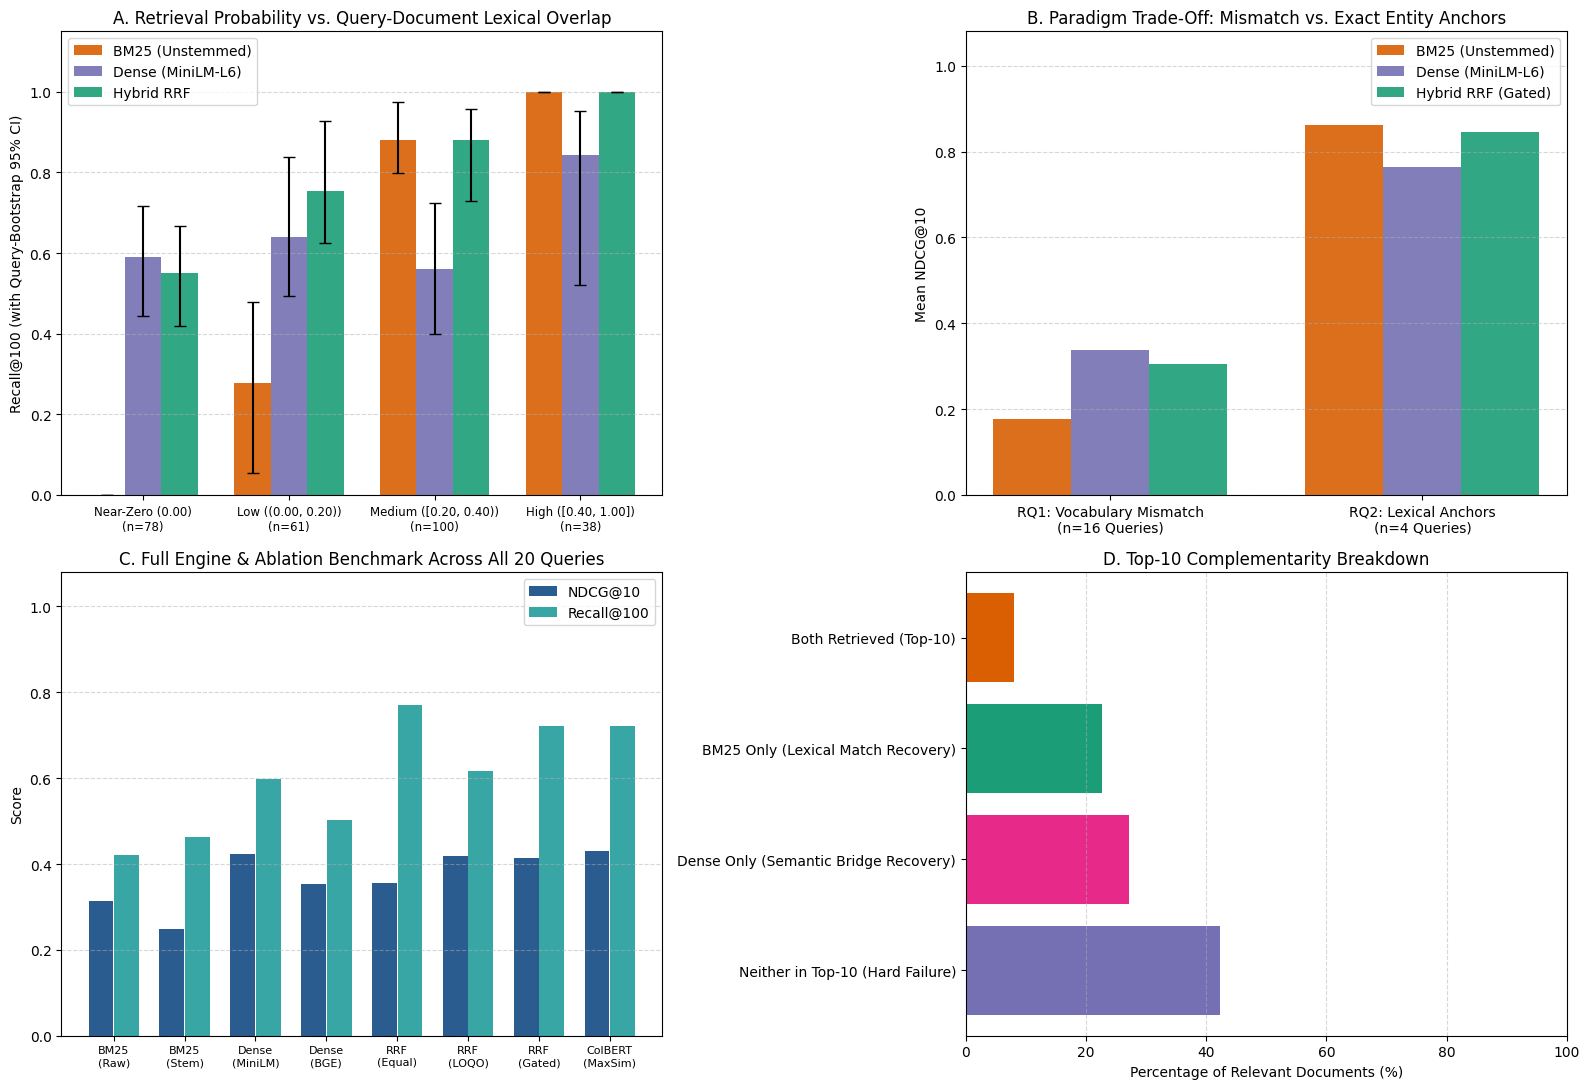

Saved high-resolution dashboard to 'final_presentation_dashboard_v3.png'.


In [ ]:
active_graded_qrels = globals().get("qrels_graded") or globals().get("qrels_modelfree_pool")
active_strict_qrels = globals().get("qrels_strict_targets") or globals().get("qrels_strict")

if "Engine C3: Hybrid RRF (Specificity-Gated)" not in metrics_df["engine"].unique():
    _tok = dense_engine.encoder.tokenizer
    _tfm = dense_engine.encoder[0].auto_model
    _sp_ids = set(_tok.all_special_ids)

    @torch.no_grad()
    def _encode_tokens(texts, max_len=96):
        enc = _tok(texts, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(dense_engine.device)
        out = _tfm(**enc)
        embs = torch.nn.functional.normalize(out.last_hidden_state, p=2, dim=-1)
        mask = enc["attention_mask"].bool()
        for sid in _sp_ids:
            mask = mask & (enc["input_ids"] != sid)
        return embs, mask

    extra_rows = []
    c3_rankings = {}
    for _, q_row in query_plan_df.iterrows():
        qid = q_row["query_id"]
        q_text = q_row["query"]
        subtype = q_row["taxonomy_subtype"]
        focus = q_row["paradigm_focus"]
        b_idx, b_scores = bm25_engine.search(q_text, top_k=500)
        d_idx, _ = dense_engine.search(q_text, top_k=500)
        max_b = float(b_scores[0]) if len(b_scores) > 0 else 0.0
        w_b = 0.60 if max_b >= 22.0 else 0.15
        c3_idx, c3_sc = fuse_lists_with_weight(b_idx, d_idx, w_bm25=w_b, rrf_k=60, top_k=100)
        c3_rankings[qid] = c3_idx
        cand_texts = [df.loc[int(i), "search_text"] for i in c3_idx]
        q_emb, q_m = _encode_tokens([q_text], max_len=48)
        d_emb, d_m = _encode_tokens(cand_texts, max_len=96)
        q_v = q_emb[0][q_m[0]]
        sim_mat = torch.einsum("qd,bkd->bqk", q_v, d_emb).masked_fill(~d_m.unsqueeze(1), -1e4)
        max_sim = sim_mat.max(dim=-1).values.sum(dim=-1).cpu().numpy()
        d_rerank_idx = c3_idx[np.argsort(max_sim)[::-1]].astype(np.int32)

        for eng_label, r_idx in [
            ("Engine C3: Hybrid RRF (Specificity-Gated)", c3_idx),
            ("Engine D: ColBERT-Style MaxSim (Rerank)", d_rerank_idx)
        ]:
            extra_rows.append({
                "query_id": qid,
                "taxonomy_subtype": subtype,
                "paradigm_focus": focus,
                "engine": eng_label,
                "NDCG@5": compute_ndcg(r_idx, active_strict_qrels[qid], k=5),
                "NDCG@10": compute_ndcg(r_idx, active_strict_qrels[qid], k=10),
                "MAP": compute_average_precision(r_idx, active_strict_qrels[qid], k=100),
                "Recall@10": compute_recall_at_k(r_idx, active_strict_qrels[qid], k=10),
                "Recall@100": compute_recall_at_k(r_idx, active_strict_qrels[qid], k=100),
                "Pool_NDCG@10": compute_ndcg(r_idx, active_graded_qrels[qid], k=10),
                "Pool_MAP": compute_average_precision(r_idx, active_graded_qrels[qid], k=100),
                "Pool_Recall@100": compute_recall_at_k(r_idx, active_graded_qrels[qid], k=100),
            })

    metrics_df = pd.concat([metrics_df, pd.DataFrame(extra_rows)], ignore_index=True)

if "Pool_NDCG@10" in metrics_df.columns and "Graded_NDCG@10" not in metrics_df.columns:
    metrics_df["Graded_NDCG@10"] = metrics_df["Pool_NDCG@10"]
    metrics_df["Graded_MAP"] = metrics_df["Pool_MAP"]
    metrics_df["Graded_Recall@100"] = metrics_df["Pool_Recall@100"]
elif "StrictTarget_NDCG@10" in metrics_df.columns and "Graded_NDCG@10" not in metrics_df.columns:
    metrics_df["Graded_NDCG@10"] = metrics_df["NDCG@10"]
    metrics_df["Graded_MAP"] = metrics_df["MAP"]
    metrics_df["Graded_Recall@100"] = metrics_df["Recall@100"]

overall_table = (
    metrics_df.groupby("engine")[
        ["NDCG@5", "NDCG@10", "MAP", "Recall@10", "Recall@100", "Graded_NDCG@10", "Graded_MAP", "Graded_Recall@100"]
    ]
    .mean()
    .round(4)
)
rq_table = (
    metrics_df.groupby(["paradigm_focus", "engine"])[
        ["NDCG@5", "NDCG@10", "MAP", "Recall@100", "Graded_NDCG@10"]
    ]
    .mean()
    .round(4)
)

print("=== COMPLETE 8-ENGINE BENCHMARK (STRICT TARGETS VS. 3-LEVEL GRADED POOL) ===")
display(overall_table)

def _assign_prop_bucket(cov):
    if cov == 0.0 or cov < 0.12:
        return "1. Near-Zero ([0.00, 0.12))"
    elif cov < 0.28:
        return "2. Low ([0.12, 0.28))"
    elif cov < 0.50:
        return "3. Medium ([0.28, 0.50))"
    else:
        return "4. High ([0.50, 1.00])"

if "prop_coverage_bucket" not in coverage_df.columns:
    coverage_df["prop_coverage_bucket"] = coverage_df["coverage"].apply(_assign_prop_bucket)

def fast_query_cluster_bootstrap_ci(df_sub, col, n_boot=1000, seed=42):
    if len(df_sub) == 0:
        return (0.0, 0.0)
    q_stats = df_sub.groupby("query_id")[col].agg(["sum", "count"]).to_numpy(dtype=np.float64)
    n_q = len(q_stats)
    if n_q <= 1:
        val = float(df_sub[col].mean())
        return (val, val)
    rng = np.random.default_rng(seed)
    idx_draws = rng.integers(0, n_q, size=(n_boot, n_q))
    sampled = q_stats[idx_draws]
    boot_means = sampled[:, :, 0].sum(axis=1) / np.maximum(sampled[:, :, 1].sum(axis=1), 1.0)
    return (float(np.percentile(boot_means, 2.5)), float(np.percentile(boot_means, 97.5)))

def run_wilcoxon_pair(df_sub, eng1, eng2, metric="NDCG@10"):
    s1 = df_sub[df_sub["engine"] == eng1].sort_values("query_id")[metric].to_numpy(dtype=np.float64)
    s2 = df_sub[df_sub["engine"] == eng2].sort_values("query_id")[metric].to_numpy(dtype=np.float64)
    if len(s1) == 0 or len(s2) == 0 or len(s1) != len(s2):
        return 1.0, 0.0
    diff = s1 - s2
    if np.all(np.isclose(diff, 0.0)):
        return 1.0, 0.0
    try:
        res = wilcoxon(diff, zero_method="zsplit", alternative="two-sided", method="approx")
        p_val = float(res.pvalue)
    except Exception:
        res = wilcoxon(diff, zero_method="wilcox", alternative="two-sided")
        p_val = float(res.pvalue)
    return p_val, float(np.mean(diff))

hybrid_main_label = (
    "Engine C3: Hybrid RRF (Specificity-Gated)"
    if "Engine C3: Hybrid RRF (Specificity-Gated)" in metrics_df["engine"].unique()
    else "Engine C2: Hybrid RRF (LOQO-Weighted)"
)
comparisons = [
    ("All Queries (n=20)", metrics_df, "Engine B1: Dense (MiniLM-L6)", "Engine A1: BM25 (Unstemmed)"),
    ("All Queries (n=20)", metrics_df, hybrid_main_label, "Engine A1: BM25 (Unstemmed)"),
    ("All Queries (n=20)", metrics_df, hybrid_main_label, "Engine B1: Dense (MiniLM-L6)"),
    ("All Queries (n=20)", metrics_df, "Engine A2: BM25 (Porter Stemmed)", "Engine A1: BM25 (Unstemmed)"),
    ("All Queries (n=20)", metrics_df, "Engine B2: Dense (BGE-Small)", "Engine B1: Dense (MiniLM-L6)"),
    ("All Queries (n=20)", metrics_df, "Engine D: ColBERT-Style MaxSim (Rerank)", hybrid_main_label),
    ("Mismatch RQ1 (n=16)", metrics_df[metrics_df["paradigm_focus"] == "Vocabulary Mismatch (RQ1)"], "Engine B1: Dense (MiniLM-L6)", "Engine A1: BM25 (Unstemmed)"),
    ("Anchors RQ2 (n=4)", metrics_df[metrics_df["paradigm_focus"] == "Lexical Anchor (RQ2 - BM25 Strength)"], "Engine A1: BM25 (Unstemmed)", "Engine B1: Dense (MiniLM-L6)"),
]

stat_rows = []
for subset_label, sub_df, e1, e2 in comparisons:
    p_raw, mean_diff = run_wilcoxon_pair(sub_df, e1, e2, metric="NDCG@10")
    p_graded, graded_diff = run_wilcoxon_pair(sub_df, e1, e2, metric="Graded_NDCG@10")
    stat_rows.append({
        "Subset": subset_label,
        "Comparison": f"{e1} vs. {e2}",
        "Strict_NDCG@10_Diff": round(mean_diff, 4),
        "Graded_NDCG@10_Diff": round(graded_diff, 4),
        "raw_p": p_raw,
        "graded_raw_p": round(p_graded, 5)
    })

stat_df = pd.DataFrame(stat_rows).sort_values("raw_p").reset_index(drop=True)
m_tests = len(stat_df)
holm_p = []
running_max = 0.0
for idx_row, row in stat_df.iterrows():
    adj = min(1.0, row["raw_p"] * (m_tests - idx_row))
    running_max = max(running_max, adj)
    holm_p.append(round(running_max, 5))
stat_df["Holm_Corrected_p"] = holm_p
stat_df["raw_p"] = stat_df["raw_p"].round(5)
stat_df.to_csv("wilcoxon_holm_significance_tests.csv", index=False)

print("\n=== 9. PAIRED WILCOXON SIGNED-RANK TESTS WITH HOLM-BONFERRONI CORRECTION ===")
display(stat_df)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
active_bucket_col = "coverage_bucket" if "coverage_bucket" in coverage_df.columns else "prop_coverage_bucket"
b_names = sorted(coverage_df[active_bucket_col].unique().tolist())
short_labels = [
    f"{b.split('. ', 1)[1] if '. ' in b else b}\n(n={len(coverage_df[coverage_df[active_bucket_col] == b])})"
    for b in b_names
]
x_b = np.arange(len(b_names))
w = 0.25

for offset, col_name, label_str, color_hex in [
    (-w, "BM25_R@100", "BM25 (Unstemmed)", "#d95f02"),
    (0.0, "Dense_R@100", "Dense (MiniLM-L6)", "#7570b3"),
    (w, "Hybrid_R@100", "Hybrid RRF", "#1b9e77"),
]:
    means, err_low, err_high = [], [], []
    for b in b_names:
        sub = coverage_df[coverage_df[active_bucket_col] == b]
        m = float(sub[col_name].mean()) if len(sub) > 0 else 0.0
        ci_l, ci_u = fast_query_cluster_bootstrap_ci(sub, col_name)
        means.append(m)
        err_low.append(max(0.0, m - ci_l))
        err_high.append(max(0.0, ci_u - m))
    axes[0, 0].bar(x_b + offset, means, w, yerr=[err_low, err_high], capsize=4, label=label_str, color=color_hex, alpha=0.9)

axes[0, 0].set_xticks(x_b)
axes[0, 0].set_xticklabels(short_labels, fontsize=8.5)
axes[0, 0].set_ylim(0, 1.15)
axes[0, 0].set_ylabel("Recall@100 (with Query-Bootstrap 95% CI)")
axes[0, 0].set_title("A. Retrieval Probability vs. Query-Document Lexical Overlap")
axes[0, 0].legend(loc="upper left")
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.5)

focus_groups = ["Vocabulary Mismatch (RQ1)", "Lexical Anchor (RQ2 - BM25 Strength)"]
x_f = np.arange(len(focus_groups))
for offset, eng_key, label_str, color_hex in [
    (-w, "Engine A1: BM25 (Unstemmed)", "BM25 (Unstemmed)", "#d95f02"),
    (0.0, "Engine B1: Dense (MiniLM-L6)", "Dense (MiniLM-L6)", "#7570b3"),
    (w, hybrid_main_label, "Hybrid RRF (Gated)", "#1b9e77"),
]:
    vals = [float(rq_table.loc[(fg, eng_key), "NDCG@10"]) for fg in focus_groups]
    axes[0, 1].bar(x_f + offset, vals, w, label=label_str, color=color_hex, alpha=0.9)

axes[0, 1].set_xticks(x_f)
axes[0, 1].set_xticklabels(["RQ1: Vocabulary Mismatch\n(n=16 Queries)", "RQ2: Lexical Anchors\n(n=4 Queries)"])
axes[0, 1].set_ylim(0, 1.08)
axes[0, 1].set_ylabel("Mean NDCG@10")
axes[0, 1].set_title("B. Paradigm Trade-Off: Mismatch vs. Exact Entity Anchors")
axes[0, 1].legend()
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.5)

candidate_plot_engines = [
    ("Engine A1: BM25 (Unstemmed)", "BM25\n(Raw)"),
    ("Engine A2: BM25 (Porter Stemmed)", "BM25\n(Stem)"),
    ("Engine B1: Dense (MiniLM-L6)", "Dense\n(MiniLM)"),
    ("Engine B2: Dense (BGE-Small)", "Dense\n(BGE)"),
    ("Engine C1: Hybrid RRF (Equal)", "RRF\n(Equal)"),
    ("Engine C2: Hybrid RRF (LOQO-Weighted)", "RRF\n(LOQO)"),
    ("Engine C3: Hybrid RRF (Specificity-Gated)", "RRF\n(Gated)"),
    ("Engine D: ColBERT-Style MaxSim (Rerank)", "ColBERT\n(MaxSim)")
]
avail_engines = [(e_key, e_lbl) for e_key, e_lbl in candidate_plot_engines if e_key in overall_table.index]
x_e = np.arange(len(avail_engines))
ndcg_vals = [float(overall_table.loc[e_key, "NDCG@10"]) for e_key, _ in avail_engines]
r100_vals = [float(overall_table.loc[e_key, "Recall@100"]) for e_key, _ in avail_engines]

axes[1, 0].bar(x_e - 0.18, ndcg_vals, 0.35, label="NDCG@10", color="#2b5c8f")
axes[1, 0].bar(x_e + 0.18, r100_vals, 0.35, label="Recall@100", color="#38a6a5")
axes[1, 0].set_xticks(x_e)
axes[1, 0].set_xticklabels([e_lbl for _, e_lbl in avail_engines], fontsize=8)
axes[1, 0].set_ylim(0, 1.08)
axes[1, 0].set_ylabel("Score")
axes[1, 0].set_title("C. Full Engine & Ablation Benchmark Across All 20 Queries")
axes[1, 0].legend()
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.5)

palette = ["#7570b3", "#e7298a", "#1b9e77", "#d95f02"][:len(comp_summary)]
axes[1, 1].barh(comp_summary["Retrieval Outcome"], comp_summary["Percentage (%)"], color=palette)
axes[1, 1].set_xlabel("Percentage of Relevant Documents (%)")
axes[1, 1].set_xlim(0, 100)
axes[1, 1].set_title("D. Top-10 Complementarity Breakdown")
axes[1, 1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("final_presentation_dashboard_v3.png", dpi=300)
plt.show()
print("Saved high-resolution dashboard to 'final_presentation_dashboard_v3.png'.")